<div style="border-left:7px solid #1A59FD; background:#F3F6FF; padding:16px 20px; border-radius:4px; font-family:Segoe UI, Arial, sans-serif;">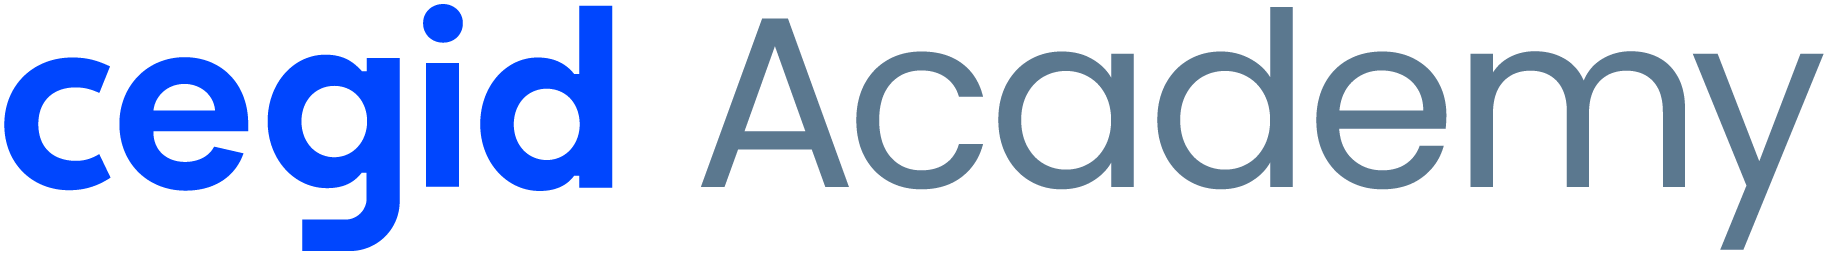<div style="font-size:22px; font-weight:700; color:#1A59FD; line-height:1.2;">Fase 2 &middot; Entendimento dos Dados</div><div style="font-size:14px; color:#0A2540; margin-top:4px;">Implementação de Modelos Analíticos com Python &nbsp;&middot;&nbsp; Projeto CRISP-DM · <i>Data Understanding</i> &nbsp;&middot;&nbsp; Versão <b>formandos</b> &nbsp;&middot;&nbsp; Apoio: <b>M1 · M2.01–M2.05</b></div><div style="margin-top:10px;"><span style="display:inline-block;background:#D6E2FF;color:#1A59FD;border:1px solid #D6E2FF;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">1. Entendimento do Negócio</span><span style="display:inline-block;background:#1A59FD;color:#FFFFFF;font-weight:600;border:1px solid #1A59FD;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">2. Entendimento dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">3. Preparação dos Dados</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">4. Modelação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">5. Avaliação</span><span style="display:inline-block;background:#FFFFFF;color:#0A2540;border:1px solid #C9D6F5;padding:3px 9px;margin:2px 3px 2px 0;border-radius:3px;font-size:12px;">6. Deployment</span></div></div>

#### Identificação do projeto

| Campo | Preenchimento |
|---|---|
| Projeto | Previsão da intenção de mudança de emprego |
| Grupo | Não indicado nos ficheiros fornecidos |
| Formandos | Não indicados nos ficheiros fornecidos |
| Data da revisão | 14/10/2026 |
| Dataset | `Data/input/Dados_RH_Mudanca_Emprego.csv` |

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Objetivo</div>Conhecer os dados antes de os transformar. Seguir o <b>workflow estruturado de AED</b> visto no M2.03 (e os gráficos do M1):<ul style="margin:4px 0 2px 0;"><li>Estrutura do dataset</li><li>Qualidade dos dados</li><li>Análise univariada</li><li>Análise bivariada</li><li>Análise multivariada</li></ul>No fim, cada problema encontrado deve dar origem a uma <b>decisão</b> para a Fase 3.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Atenção</div>Nesta fase <b>observa-se, não se transforma</b>. A limpeza, o encoding e o scaling são feitos na Fase 3 (Data Preparation). Visualizar ≠ decorar gráficos — visualizar = <b>interpretar dados</b>.</div>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Data leakage na exploração</div>A AED é feita sobre o dataset completo para <b>compreender</b> os dados — isso está correto. O risco surge quando se <b>tomam decisões de modelação</b> com base em relações com o target calculadas com todas as linhas (incluindo as que vão ser o teste):<ul style="margin:4px 0 2px 0;"><li>escolher variáveis pela correlação ou pelo p-value com o target;</li><li>fixar limites de outliers, categorias raras ou intervalos de discretização a partir destes resultados e reutilizá-los tal e qual;</li><li>ajustar aqui um scaler, um PCA ou uma imputação e aproveitá-los na modelação.</li></ul>Nesta fase <b>regista-se</b> o que se observa; os valores concretos (medianas, limites, categorias, variáveis selecionadas) são <b>recalculados só no treino</b> na Fase 3.</div>

**Índice**

0. Configuração · 1. Recolha e descrição inicial · 2. Estrutura · 3. Qualidade · 4. Análise univariada · 5. Análise bivariada · 6. Análise multivariada · 7. Síntese e decisões

### 0. Configuração
<hr>

Preencher a configuração do projeto. Nas secções seguintes, as células marcadas como **[Classificação]**, **[Regressão]** ou **[Clustering]** só se aplicam a esse tipo de problema — mantenham apenas as que se aplicam ao vosso caso.

**0.1 Bibliotecas**
- Importar `numpy`, `pandas`, `matplotlib.pyplot`, `seaborn` e `scipy.stats`.
- Configurar `pd.set_option("display.max_columns", None)` e `sns.set_theme(style="whitegrid")`.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

**0.2 Configuração do projeto** (usar exatamente os mesmos valores no notebook 03)
- Criar as variáveis: `PROJETO` (nome curto, ex.: `"HR-Intern-Retention"`), `DATA_PATH` (caminho do dataset em `Data/input/`), `TARGET` (variável-alvo; em clustering `None` ou uma variável de referência), `PROBLEM_TYPE` (`"classificacao"`, `"regressao"` ou `"clustering"`), `ID_COLS` (lista de identificadores), `RANDOM_STATE = 42` e `TEST_SIZE = 0.2`.

In [2]:
projeto = "RH_Mudanca_Emprego"
data_path = "Data/input/Dados_RH_Mudanca_Emprego.csv"
target = "procura_mudanca_emprego"
problem_type = "classificacao"
id_cols = ["id_candidato"]
random_state = 42
test_size = 0.2

**0.3 Estrutura de pastas**
- Criar (se não existirem) as pastas `Data/input`, `Data/output`, `Data/analytics` e `Data/models` — sugestão: `pathlib.Path(...).mkdir(parents=True, exist_ok=True)`.
- (Opcional) Criar uma função `guardar_figura(nome)` que grava o gráfico atual em `Data/analytics/`.

In [3]:
from pathlib import Path

pastas = [
    "Data/input",
    "Data/output",
    "Data/analytics",
    "Data/models"
]

for pasta in pastas:
    Path(pasta).mkdir(parents=True, exist_ok=True)

print("Estrutura de pastas criada com sucesso.")

# Guardar também os gráficos apresentados no notebook.
numero_figura = 0
mostrar_figura = plt.show
def guardar_e_mostrar(*args, **kwargs):
    global numero_figura
    for numero in plt.get_fignums():
        numero_figura += 1
        figura = plt.figure(numero)
        figura.savefig(f'Data/analytics/02_grafico_{numero_figura:02d}.png',
                       dpi=150, bbox_inches='tight')
    mostrar_figura(*args, **kwargs)
    plt.close('all')
plt.show = guardar_e_mostrar


Estrutura de pastas criada com sucesso.


### 1. Recolha e descrição inicial dos dados
<hr>

- Origem do dataset (fonte, link, data de extração)
- Número de registos e de variáveis
- O que representa cada linha (unidade de análise)?
- Tipo de variáveis (numéricas, categóricas, temporais, texto)
- Unidade de medida de cada variável (€, %, meses, toneladas, …)

***Objetivo:*** perceber "o que tenho em mãos".

**Fonte utilizada:** CSV disponibilizado para este projeto. O URL original, a licença e a data de recolha não constam dos ficheiros. A análise usa o CSV real; não foi efetuada uma recolha própria nesta revisão. Não existem variáveis temporais.

**1.1 Carregar o dataset**
- Ler o ficheiro com `pd.read_csv` (ou `pd.read_excel`) para um DataFrame `df`.
- Mostrar o número de registos e de variáveis (`.shape`) e as primeiras linhas (`.head()`).

In [4]:
df = pd.read_csv(data_path)

display(df.shape)
display(df.head(5))



(19158, 14)

,id_candidato,cidade,indice_desenvolvimento_cidade,genero,experiencia_relevante,inscricao_universidade,nivel_educacao,area_formacao,anos_experiencia,dimensao_empresa,tipo_empresa,anos_desde_ultimo_emprego,horas_formacao,procura_mudanca_emprego
0,760695,Zona_049,0.910,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",6 anos,500 a 999,Empresa privada,1 ano,21,Não
1,789493,Zona_006,0.920,Feminino,Com experiência relevante,Não inscrito,Mestrado,Humanidades,Mais de 20 anos,100 a 500,Startup financiada,2 anos,74,Não
2,211612,Zona_007,0.924,NaN,Com experiência relevante,Não inscrito,Licenciatura,"Ciência, Tecnologia, Engenharia e Matemática",9 anos,10 a 49,Empresa privada,1 ano,94,Não
3,521686,Zona_065,0.624,Masculino,Com experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",15 anos,10000 ou mais,Empresa privada,1 ano,75,Não
4,146611,Zona_030,0.698,Masculino,Sem experiência relevante,Não inscrito,Mestrado,"Ciência, Tecnologia, Engenharia e Matemática",12 anos,500 a 999,ONG,1 ano,157,Não


##### Análise e Interpretação

> *Quantos registos e variáveis existem? O que representa cada linha (unidade de análise)?*

**Resposta:**

O dataset contém 19158 registos e 14 variáveis. Cada linha corresponde a um registo de um candidato.

<hr>

**1.2 Resumo das variáveis**
- Construir uma tabela com, para cada coluna: tipo (`dtypes`), nº de valores distintos (`nunique`) e 2–3 exemplos de valores.
- Usar esta tabela para preencher o dicionário de dados abaixo.

In [5]:
tabela_variaveis = pd.DataFrame({
    "data_type": df.dtypes,
    "valores_distintos": df.nunique (),
    "exemplos": [df[coluna].dropna().unique()[:3]
                 for coluna in df.columns]
})

display(tabela_variaveis)

,data_type,valores_distintos,exemplos
id_candidato,int64,19158,"[760695, 789493, 211612]"
cidade,str,123,"[Zona_049, Zona_006, Zona_007]"
indice_desenvolvimento_cidade,float64,93,"[0.91, 0.92, 0.924]"
genero,str,3,"[Feminino, Masculino, Outro]"
experiencia_relevante,str,2,"[Com experiência relevante, Sem experiência re..."
inscricao_universidade,str,3,"[Não inscrito, Curso a tempo inteiro, Curso a ..."
nivel_educacao,str,5,"[Licenciatura, Mestrado, Ensino Secundário]"
area_formacao,str,6,"[Ciência, Tecnologia, Engenharia e Matemática,..."
anos_experiencia,str,22,"[6 anos, Mais de 20 anos, 9 anos]"
dimensao_empresa,str,8,"[500 a 999, 100 a 500, 10 a 49]"


**Resposta:**

Existem identificadores, duas numéricas explicativas e variáveis categóricas nominais e ordinais. `anos_experiencia` inclui intervalos abertos e será representada por códigos ordinais, não por durações exatas. `anos_desde_ultimo_emprego` inclui “Nunca” e mantém-se categórica. O alvo Sim/Não será codificado em 1/0.

**Dicionário de dados** (completar)

 Coluna | Significado | Tipo de variável | Unidade / Exemplos / Notas |
|---|---|---|---|
| `id_candidato` | Identificador único do candidato | Identificador | Ex.: 760695, 789493 |
| `cidade` | Cidade/zona de residência do candidato | Categórica nominal | Ex.: Zona_049, Zona_006 |
| `indice_desenvolvimento_cidade` | Índice de desenvolvimento da cidade | Numérica contínua | Valores entre 0 e 1 |
| `genero` | Género do candidato | Categórica nominal | Feminino, Masculino, Outro |
| `experiencia_relevante` | Indica se o candidato possui experiência profissional relevante | Categórica nominal | Com experiência relevante / Sem experiência relevante |
| `inscricao_universidade` | Situação de inscrição universitária do candidato | Categórica nominal | Não inscrito, Curso a tempo inteiro, Curso a tempo parcial |
| `nivel_educacao` | Nível de educação do candidato | Categórica ordinal | Ensino Secundário, Licenciatura, Mestrado, etc. |
| `area_formacao` | Área de formação do candidato | Categórica nominal | Ciência, Tecnologia, Engenharia e Matemática, etc. |
| `anos_experiencia` | Anos de experiência profissional | Categórica ordinal | Ex.: 6 anos, 9 anos, Mais de 20 anos |
| `dimensao_empresa` | Dimensão da empresa | Categórica ordinal | Ex.: 10 a 49, 100 a 500, 500 a 999 |
| `tipo_empresa` | Tipo de empresa | Categórica nominal | Empresa privada, Startup financiada, ONG |
| `anos_desde_ultimo_emprego` | Tempo desde o último emprego | Categórica ordinal | Ex.: 1 ano, 2 anos, Mais de 4 anos |
| `horas_formacao` | Número de horas de formação | Numérica discreta | Horas |
| `procura_mudanca_emprego` | Indica se o candidato procura mudar de emprego | Categórica nominal (binária) | Não / Sim — variável-alvo |

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de variáveis (M1 · M2.01):<ul style="margin:4px 0 2px 0;"><li><b>Numérica contínua</b> — qualquer valor num intervalo (salário, idade, fare) → histograma, boxplot;</li><li><b>Numérica discreta</b> — contagens (nº de irmãos, meses) → histograma / bar plot;</li><li><b>Categórica nominal</b> — sem ordem (departamento, curso) → bar plot / countplot;</li><li><b>Categórica ordinal</b> — com ordem natural (nível de escolaridade, classe do bilhete);</li><li><b>Identificador</b> — não tem valor explicativo (ID) → excluir da modelação.</li></ul></div>

### 2. Análise da estrutura dos dados
<hr>

- `df.head()`, `df.info()`, `df.describe()`
- Os tipos de dados estão corretos? (ex.: datas lidas como texto, números como `object`)
- Existem colunas irrelevantes, identificadores ou colunas constantes?
- Existem variáveis que **não estariam disponíveis no momento da previsão** (risco de *data leakage*)?

***Objetivo:*** verificar problemas estruturais.

**2.1 Tipos e não-nulos**
- Aplicar `df.info()`.

In [6]:
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_candidato                   19158 non-null  int64  
 1   cidade                         19158 non-null  str    
 2   indice_desenvolvimento_cidade  19158 non-null  float64
 3   genero                         14650 non-null  str    
 4   experiencia_relevante          19158 non-null  str    
 5   inscricao_universidade         18772 non-null  str    
 6   nivel_educacao                 18698 non-null  str    
 7   area_formacao                  16345 non-null  str    
 8   anos_experiencia               19093 non-null  str    
 9   dimensao_empresa               13220 non-null  str    
 10  tipo_empresa                   13018 non-null  str    
 11  anos_desde_ultimo_emprego      18735 non-null  str    
 12  horas_formacao                 19158 non-null  int64  
 1

In [7]:
print ("ISNA SUM - COLUNAS COM TOTAL DE VALORES NULOS:") 
display (df.isna().sum())

ISNA SUM - COLUNAS COM TOTAL DE VALORES NULOS:


id_candidato                        0
cidade                              0
indice_desenvolvimento_cidade       0
genero                           4508
experiencia_relevante               0
inscricao_universidade            386
nivel_educacao                    460
area_formacao                    2813
anos_experiencia                   65
dimensao_empresa                 5938
tipo_empresa                     6140
anos_desde_ultimo_emprego         423
horas_formacao                      0
procura_mudanca_emprego             0
dtype: int64

##### Análise e Interpretação

> *Os tipos de dados estão corretos? Há colunas com valores em falta?*

**Resposta:**

- Existem valores em falta em várias colunas, com maior relevância nas variaveis: tipo_empresa,dimensao_empresa, genero, area_formacao
- A experiência está em texto e será codificada numa escala ordinal; os extremos não representam anos exatos. O tempo desde o último emprego fica categórico por incluir “Nunca”.

<hr>

**2.2 Estatística descritiva geral**
- Aplicar `df.describe(include="all")` (dica: `.T` torna a tabela mais legível).

In [8]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_candidato,19158.0,NaN,NaN,NaN,547509.22043,259482.271599,100000.0,323343.5,546871.0,770871.5,999982.0
cidade,19158,123,Zona_006,4355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
indice_desenvolvimento_cidade,19158.0,NaN,NaN,NaN,0.828848,0.123362,0.448,0.74,0.903,0.92,0.949
genero,14650,3,Masculino,13221,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experiencia_relevante,19158,2,Com experiência relevante,13792,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inscricao_universidade,18772,3,Não inscrito,13817,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nivel_educacao,18698,5,Licenciatura,11598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_formacao,16345,6,"Ciência, Tecnologia, Engenharia e Matemática",14492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anos_experiencia,19093,22,Mais de 20 anos,3286,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dimensao_empresa,13220,8,50 a 99,3083,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##### Análise e Interpretação

> *Há valores mínimos/máximos estranhos? Que variáveis têm escalas muito diferentes?*

**Resposta:**

- Não existem valores mínimos/máximos que consideremos desaquados nas variaveis numéricas.
<hr>

**2.3 Listas de variáveis, identificadores e colunas constantes**
- Criar as listas `num_cols` (numéricas) e `cat_cols` (categóricas), **sem** o target nem os `ID_COLS` — `select_dtypes`.
- Identificar colunas com um valor distinto por linha (possíveis identificadores) e colunas constantes.

In [9]:
num_cols = [col for col in df.select_dtypes(include="number").columns
            if col != target and col not in id_cols]
cat_cols = [col for col in df.select_dtypes(include=["object", "string"]).columns
            if col != target and col not in id_cols]
print("Variáveis numéricas:", num_cols)
print("Variáveis categóricas:", cat_cols)
print("Possíveis identificadores:", df.columns[df.nunique() == len(df)].tolist())
print("Colunas constantes:", df.columns[df.nunique(dropna=False) <= 1].tolist())

Variáveis numéricas: ['indice_desenvolvimento_cidade', 'horas_formacao']
Variáveis categóricas: ['cidade', 'genero', 'experiencia_relevante', 'inscricao_universidade', 'nivel_educacao', 'area_formacao', 'anos_experiencia', 'dimensao_empresa', 'tipo_empresa', 'anos_desde_ultimo_emprego']
Possíveis identificadores: ['id_candidato']


Colunas constantes: []


**Resposta:**

Exclui-se `id_candidato` da modelação, mantendo-o para rastrear as previsões. Não há colunas constantes nem uma variável que revele diretamente o alvo. A disponibilidade das características no momento da previsão é uma hipótese a confirmar no contexto de utilização.

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Sinais de alarme de leakage</div>Desconfiem de uma variável quando:<ul style="margin:4px 0 2px 0;"><li>tem correlação quase perfeita com o target ou separa as classes quase sem erro;</li><li>é registada <b>depois</b> do acontecimento que se quer prever (datas de saída, estado final, avaliações finais, montantes pagos no fim);</li><li>é o target escrito de outra forma (no Titanic, <code>alive</code>) ou uma transformação dele;</li><li>é um identificador ou uma data de registo que reflete a ordem de recolha e, por acaso, se relaciona com o target;</li><li>é um agregado calculado sobre um período que inclui o futuro (ex.: total de compras do ano, quando se prevê em março).</li></ul>Resultados “bons demais” (accuracy ou R² perto de 1) são, na maioria das vezes, sinal de leakage e não de um bom modelo.</div>

### 3. Análise de qualidade dos dados
<hr>

**Valores em falta** — quantos? em que variáveis? que percentagem por coluna? há padrão (MCAR / MAR / MNAR)?

**Valores duplicados** — existem? são legítimos (duas pessoas iguais) ou erros de registo?

**Inconsistências** — valores negativos onde não deveriam existir, percentagens > 100, categorias escritas de formas diferentes (`"HR"`, `"hr "`), unidades misturadas, **códigos de missing disfarçados** (999, −1, `fare = 0`).

**Colunas redundantes** — a mesma informação noutra forma (no Titanic: `class` = `pclass`, `embark_town` = `embarked`, e `alive` = **o próprio alvo disfarçado** → *leakage*).

***Objetivo:*** avaliar a qualidade dos dados.

**3.1 Valores em falta**
- Tabela com nº de nulos e % de nulos por coluna, ordenada — `isnull().sum()`, `isnull().mean()`.

In [10]:
#df.isnull().sum()

#df.isnull().mean()

tabela_nulos = pd.DataFrame ({
    "nulos": df.isnull().sum(),
    "percentagem_nulos": df.isnull().mean() * 100
})

tabela_nulos = tabela_nulos.sort_values("nulos", ascending= False)
tabela_nulos["percentagem_nulos"] = tabela_nulos["percentagem_nulos"].round(2)
display(tabela_nulos)

,nulos,percentagem_nulos
tipo_empresa,6140,32.05
dimensao_empresa,5938,30.99
genero,4508,23.53
area_formacao,2813,14.68
nivel_educacao,460,2.40
anos_desde_ultimo_emprego,423,2.21
inscricao_universidade,386,2.01
anos_experiencia,65,0.34
id_candidato,0,0.00
cidade,0,0.00


##### Análise e Interpretação

> *Quantos valores faltam e em que variáveis? A ausência parece ao acaso (MCAR) ou ligada a outras variáveis (MAR/MNAR)?*

**Resposta:**
- Identificamos valores em falta em 8 das 14 variaveis. 57.14% das colunas tem valores em falta.
- A maior concentração ocorre em 4 variaveis: tipo_empresa (32.05%), dimensao_empresa(30.99%), genero(23.53%), area_formacao(14.68%). 
- As seguintes 4 variaveis com valores nulos, apresentam percentagens inferiores a 2.5% (nivel_educacao, anos_desde_ultimo_emprego, inscricao_universidade, anos_experencia).
- As restantes 6 não têm valores nulos incluindo a variavel alvo. 

- Nota: Nesta fase ainda não é possível determinar o motivo da ausência de valores, esta questão será avaliada na fase de análise da destribuição dos valores em falta e da sua relação com outras variáveis.


<hr>

**3.2 Heatmap de valores nulos**
- `sns.heatmap(df.isnull(), cbar=False)`.

<Axes: >

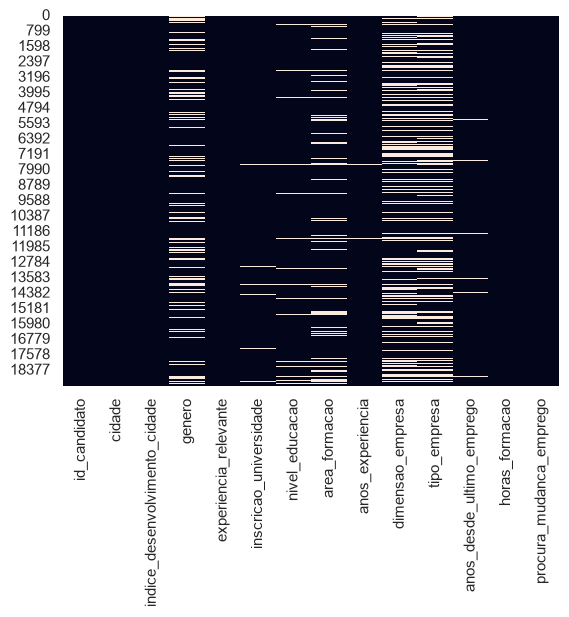

In [11]:
sns.heatmap(df.isnull(), cbar=False)

##### Análise e Interpretação

> *Os nulos concentram-se em certas colunas ou linhas? Há algum padrão?*

**Resposta:**

-  Visualmente, os valores em falta encontram-se distribuídos ao longo dos registos, não sendo evidente um padrão específico apenas através do heatmap.

<hr>

**3.3 Duplicados**
- Contar linhas duplicadas (`duplicated().sum()`) e IDs repetidos.

In [12]:
display(df.duplicated().sum())

display(df["id_candidato"].duplicated().sum())

np.int64(0)

np.int64(0)

##### Análise e Interpretação

> *Existem duplicados? São erros de registo ou casos legítimos?*

**Resposta:**

- Não foram identificados duplicados nem nos registos integrais nem no ID.

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Dados agrupados e dados temporais</div><ul style="margin:4px 0 2px 0;"><li><b>Várias linhas da mesma entidade</b> (o mesmo cliente, doente, estagiário ou máquina): com uma divisão aleatória, a mesma entidade fica no treino e no teste e o modelo é avaliado sobre casos que já “conhece”. A divisão tem de ser feita <b>por entidade</b> (<code>GroupShuffleSplit</code>, <code>GroupKFold</code>).</li><li><b>Dados com ordem temporal</b> (vendas, séries, registos datados): uma divisão aleatória usa o futuro para prever o passado. A divisão deve ser <b>cronológica</b> (treino = período mais antigo, teste = período mais recente) e a validação cruzada feita com <code>TimeSeriesSplit</code>.</li><li><b>Duplicados exatos</b> que fiquem um no treino e outro no teste inflacionam o resultado: tratam-se antes da divisão (Fase 3, secção 2).</li></ul>Registem na síntese (secção 7) se o vosso dataset tem alguma destas estruturas.</div>

**3.4 Intervalos das variáveis numéricas**
- Mostrar mínimo e máximo de cada numérica e assinalar as que têm valores negativos.

In [13]:
intervalos_num = df[num_cols].agg(["min","max"]).round(2).T

display(intervalos_num)

,min,max
indice_desenvolvimento_cidade,0.45,0.95
horas_formacao,1.00,336.00


##### Análise e Interpretação

> *Há valores impossíveis (negativos, % > 100, códigos como 999 ou 0 improvável)?*

**Resposta:**

- Não foram identificados valores negativos nas variaveis numéricas. 
- Os valores apresentados em ambas as variaveis são plausiveis.
- Não foram detetados valores impossíveis nem suspeitos.

<hr>

**3.5 Categorias escritas de formas diferentes**
- Para cada categórica, comparar o nº de categorias antes e depois de `str.strip().str.lower()` e listar as categorias.

In [14]:
resultados = []

for col in cat_cols:
    antes = df[col].nunique()
    depois = df[col].str.strip().str.lower().nunique()
    
    resultados.append([col, antes, depois])

tabela_categorias = pd.DataFrame(
    resultados,
    columns=["variavel", "categorias_antes", "categorias_depois"]
)

display(tabela_categorias)


,variavel,categorias_antes,categorias_depois
0,cidade,123,123
1,genero,3,3
2,experiencia_relevante,2,2
3,inscricao_universidade,3,3
4,nivel_educacao,5,5
5,area_formacao,6,6
6,anos_experiencia,22,22
7,dimensao_empresa,8,8
8,tipo_empresa,6,6
9,anos_desde_ultimo_emprego,6,6


##### Análise e Interpretação

> *Há categorias duplicadas por diferenças de escrita? Que correções serão necessárias na Fase 3?*

**Resposta:**

- Não existe nenhuma categoria duplicada.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Tipos de <i>missing data</i> (M3.02):<ul style="margin:4px 0 2px 0;"><li><b>MCAR</b> — em falta completamente ao acaso, sem padrão;</li><li><b>MAR</b> — a ausência depende de outras variáveis observadas;</li><li><b>MNAR</b> — a ausência depende do próprio valor em falta (ex.: salários altos não declarados).</li></ul>O tipo de missing condiciona a estratégia a adotar na Fase 3.</div>

### 4. Análise univariada
<hr>

**Variáveis numéricas** — média, mediana, desvio padrão, mínimo/máximo, assimetria (*skewness*), histogramas, boxplots, outliers (IQR e Z-score), distribuição unimodal ou multimodal.

**Variáveis categóricas** — frequência das categorias, categorias raras.

**Variável-alvo** — balanceamento das classes (classificação) ou distribuição (regressão). **Muito importante!**

***Objetivo:*** ganhar intuição sobre os dados.

**4.1 "Ficha de identidade" das numéricas (M2.03)**
- Tabela com média, mediana, moda, desvio padrão, IQR, amplitude, coeficiente de variação (%), `skew` e `kurtosis`.

In [15]:
v_numericas = pd.DataFrame({
    "media": df[num_cols].mean(),
    "mediana": df[num_cols].median(),
    "moda": df[num_cols].mode().iloc[0],
    "minimo": df[num_cols].min(),
    "máximo": df[num_cols].max(),
    "desvio_padrao": df[num_cols].std(),
    "IQR": df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    "amplitude": df[num_cols].max() - df[num_cols].min(),
    "coef_variacao_%": df[num_cols].std() / df[num_cols].mean() * 100,
    "skew": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt()
})

display(v_numericas)



,media,mediana,moda,minimo,máximo,desvio_padrao,IQR,amplitude,coef_variacao_%,skew,kurtosis
indice_desenvolvimento_cidade,0.828848,0.903,0.92,0.448,0.949,0.123362,0.18,0.501,14.883520,-0.995428,-0.538532
horas_formacao,65.366896,47.000,28.00,1.000,336.000,60.058462,65.00,335.000,91.879017,1.819237,3.840539


**Resposta:**

No índice de desenvolvimento, a mediana é cerca de 0,90 e a assimetria é negativa (aproximadamente −1). Uma diferença de cerca de 0,07 face à média deve ser lida na escala de 0 a 1.

Nas horas de formação, a mediana é 47 horas e a média ronda 65 horas. A assimetria positiva (cerca de 1,82) e a dispersão elevada justificam estudar `log1p` e usar uma escala robusta na preparação.

**4.2 Histogramas com KDE**
- Um histograma (`sns.histplot(..., kde=True)`) por variável numérica, com a média e a mediana assinaladas.

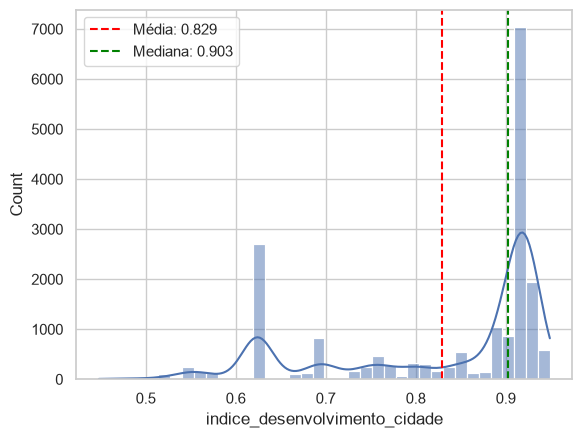

In [16]:

hist_idc = df["indice_desenvolvimento_cidade"].dropna() 

sns.histplot(hist_idc, kde=True) 

plt.axvline(hist_idc.mean(), color="red", linestyle="--",
            label=f"Média: {hist_idc.mean():.3f}")
plt.axvline(hist_idc.median(), color="green", linestyle="--",
            label=f"Mediana: {hist_idc.median():.3f}")

plt.legend()
plt.show()







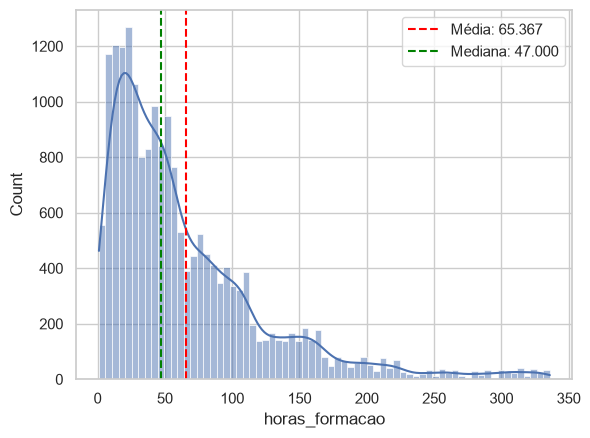

In [17]:
hist_h_formacao = df["horas_formacao"].dropna()

sns.histplot(hist_h_formacao, kde= True)

plt.axvline(hist_h_formacao.mean(), color = "red", linestyle = "--",
            label = f"Média: {hist_h_formacao.mean():.3f}")

plt.axvline(hist_h_formacao.median(), color = "green", linestyle = "--",
            label = f"Mediana: {hist_h_formacao.median():.3f}")

plt.legend()
plt.show()

##### Análise e Interpretação

> *As distribuições são unimodais ou multimodais? Simétricas ou assimétricas?*

**Resposta:**

- **Índice de desenvolvimento da cidade:** multimodal e assimétrico à esquerda, com média inferior à mediana.
- **Horas de formação:** predominantemente unimodal e assimétrico à direita, com média superior à mediana.


<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Leitura (M2.03/M2.04): média ≫ mediana → assimetria à direita; |skew| > 1 → muito assimétrica; curtose alta → caudas pesadas (mais outliers); CV alto → grande dispersão relativa.</div>

**4.3 Boxplots**
- Um boxplot por variável numérica.

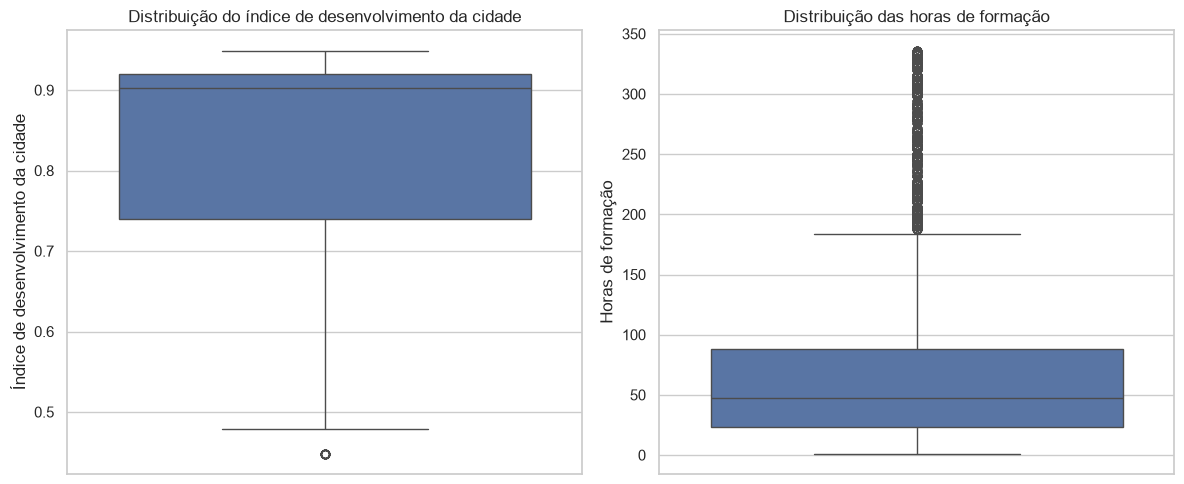

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot do índice de desenvolvimento da cidade
sns.boxplot(y=df["indice_desenvolvimento_cidade"].dropna(), ax=axes[0])
axes[0].set_title("Distribuição do índice de desenvolvimento da cidade")
axes[0].set_ylabel("Índice de desenvolvimento da cidade")

# Boxplot das horas de formação
sns.boxplot(y=df["horas_formacao"].dropna(), ax=axes[1])
axes[1].set_title("Distribuição das horas de formação")
axes[1].set_ylabel("Horas de formação")

plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Que variáveis apresentam pontos para lá dos bigodes? Parecem erros ou valores reais?*

**Resposta:**

- A variável `horas_formacao` apresenta vários valores acima do "bigode" superior, indicando a presença de **outliers elevados**, que parecem ser valores reais.

- O `indice_desenvolvimento_cidade` apresenta apenas alguns **outliers inferiores**, que também parecem plausíveis e não erros.

- Em conclusão assumios que os dados nos parecem figdignos para proceder com a análise sem qualquer alteração nesta fase.
<hr>

**4.4 Normalidade (M2.04)**
- QQ-plot de cada numérica (`stats.probplot(..., dist="norm", plot=ax)`).
- Teste de Shapiro-Wilk (`stats.shapiro`) numa tabela com W, p-value e conclusão.

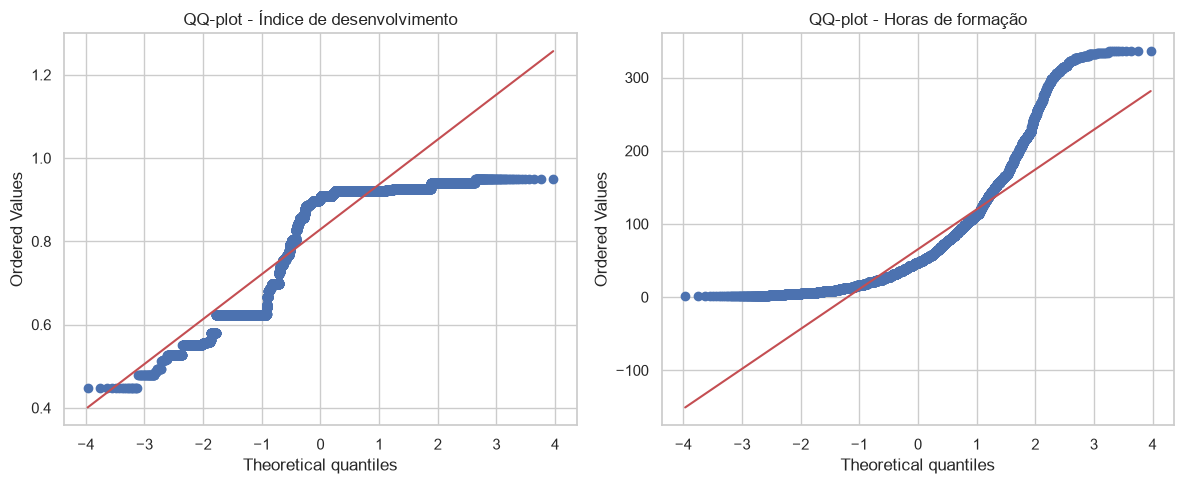

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Índice de desenvolvimento da cidade
stats.probplot(
    df["indice_desenvolvimento_cidade"].dropna(),
    dist="norm",
    plot=ax[0]
)
ax[0].set_title("QQ-plot - Índice de desenvolvimento")

# Horas de formação
stats.probplot(
    df["horas_formacao"].dropna(),
    dist="norm",
    plot=ax[1]
)
ax[1].set_title("QQ-plot - Horas de formação")

plt.tight_layout()
plt.show()

In [20]:
# Para N > 5 000, o valor-p de Shapiro-Wilk pode perder precisão.
# Usamos uma amostra reprodutível de até 5 000 observações por variável.
resultados_shapiro = {}
for coluna in num_cols:
    valores = df[coluna].dropna()
    amostra = valores.sample(n=min(5000, len(valores)), random_state=random_state)
    w, p = stats.shapiro(amostra)
    resultados_shapiro[coluna] = {
        'n': len(amostra), 'W': w, 'p_value': p,
        'conclusao': 'Rejeitar normalidade' if p < 0.05 else 'Não rejeitar normalidade'
    }
# As duas variáveis ficam lado a lado, conforme a análise existente.
shapiro = pd.DataFrame(resultados_shapiro)
display(shapiro)
print('Valores-p em notação científica:')
for coluna, resultado in resultados_shapiro.items():
    print(f"{coluna}: {resultado['p_value']:.3e}")

,indice_desenvolvimento_cidade,horas_formacao
n,5000,5000
W,0.772109,0.827074
p_value,0.0,0.0
conclusao,Rejeitar normalidade,Rejeitar normalidade


Valores-p em notação científica:
indice_desenvolvimento_cidade: 4.428e-64
horas_formacao: 7.144e-59


**Resposta:**

Os QQ-plots mostram desvios da linha de referência nas duas variáveis. Shapiro-Wilk, numa amostra aleatória de até 5 000 registos, rejeita a normalidade a 5%. Os valores-p são apresentados em notação científica para não os arredondar para zero. O teste é sensível à dimensão da amostra; a forma dos gráficos e a assimetria ajudam a avaliar a relevância dos desvios. Normalidade das variáveis explicativas não é um requisito da regressão logística ou das árvores.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>H0 do Shapiro-Wilk: os dados seguem uma distribuição normal. Se p &lt; 0,05 rejeita-se a normalidade → preferir mediana/IQR, testes não paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) ou uma transformação (log). Com amostras grandes o teste rejeita com facilidade: ler sempre em conjunto com o QQ-plot. Para n &gt; 5000 o <code>scipy</code> avisa que o p-value pode não ser exato.</div>

**4.5 Deteção de outliers (M2.04)**
- Criar uma função `conta_outliers(s)` que devolva os limites IQR e o nº de outliers por IQR (1,5×), Z-score (|z| > 3) e percentis (fora de P1–P99).
- Aplicar a todas as numéricas e apresentar numa tabela.

In [21]:
import numpy as np
import pandas as pd
from scipy.stats import zscore

def conta_outliers(s):
    s = s.dropna()

    # Limites pelo método do IQR
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    n_iqr = ((s < limite_inferior) | (s > limite_superior)).sum()

    # Outliers pelo Z-score
    n_zscore = (np.abs(zscore(s)) > 3).sum()

    # Outliers pelos percentis P1-P99
    p1 = s.quantile(0.01)
    p99 = s.quantile(0.99)
    n_percentis = ((s < p1) | (s > p99)).sum()

    return pd.Series({
        "limite_inferior_IQR": limite_inferior,
        "limite_superior_IQR": limite_superior,
        "outliers_IQR": n_iqr,
        "outliers_Z-score": n_zscore,
        "outliers_percentis": n_percentis
    })

# Selecionar todas as variáveis numéricas
variaveis_numericas = num_cols

# Aplicar a função a todas as variáveis
tabela_outliers = df[variaveis_numericas].apply(conta_outliers).T

display(tabela_outliers.round(2))

,limite_inferior_IQR,limite_superior_IQR,outliers_IQR,outliers_Z-score,outliers_percentis
indice_desenvolvimento_cidade,0.47,1.19,17.0,17.0,257.0
horas_formacao,-74.50,185.50,984.0,450.0,294.0


**Resposta:**

Os métodos identificam quantidades diferentes porque usam regras distintas. O Z-score é menos adequado a distribuições assimétricas; IQR e percentis também sinalizam valores raros plausíveis. Não há evidência para apagar automaticamente estas observações.

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div><ul style="margin:4px 0 2px 0;"><li><b>Z-score</b> funciona melhor em distribuições aproximadamente normais;</li><li><b>IQR</b> é mais robusto em distribuições assimétricas;</li><li>Nem todos os outliers são erros: podem representar informação rara mas importante — <b>ver quem são</b> (ex.: no Titanic, os outliers de <code>fare</code> são sobretudo passageiros de 1.ª classe).</li></ul></div>

**4.7 Variáveis categóricas (M2.03)**
- Para cada categórica: nº de categorias, moda, tabela de frequências (absolutas e %) e `countplot`.

cidade: 123 categorias; moda: Zona_006


,Frequência absoluta,Percentagem (%)
cidade,,
Zona_006,4355,22.73
Zona_065,2702,14.10
Zona_049,1533,8.00
Zona_014,1336,6.97
Zona_050,845,4.41
...,...,...
Zona_021,3,0.02
Zona_013,3,0.02
Zona_026,3,0.02


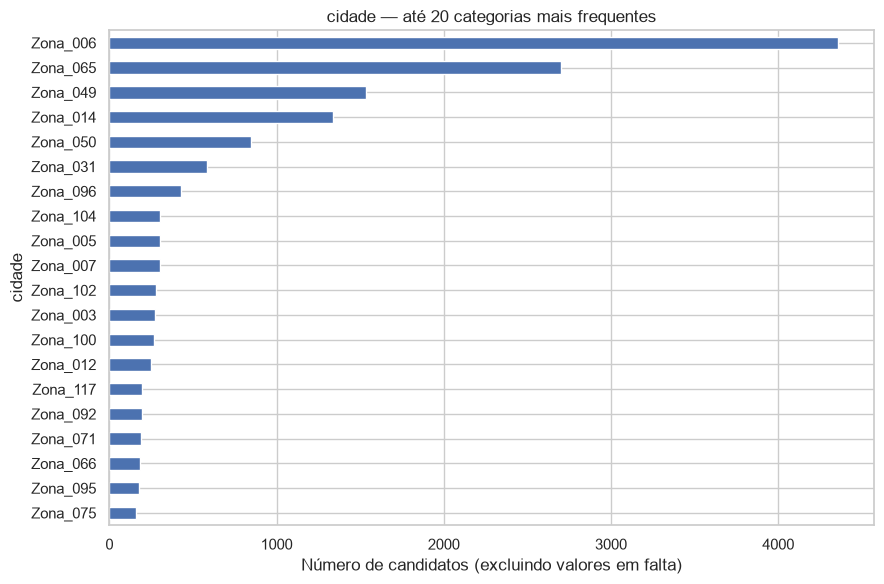

genero: 3 categorias; moda: Masculino


,Frequência absoluta,Percentagem (%)
genero,,
Masculino,13221,90.25
Feminino,1238,8.45
Outro,191,1.30


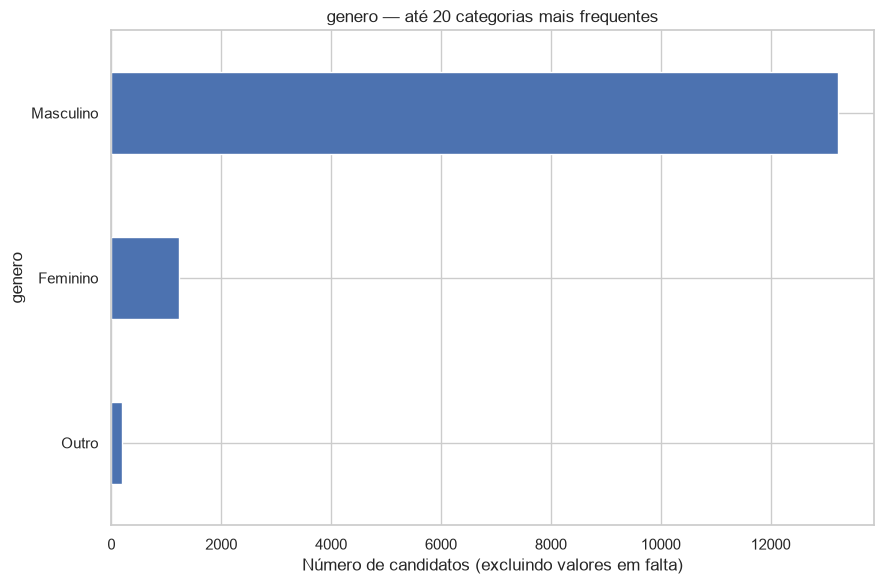

experiencia_relevante: 2 categorias; moda: Com experiência relevante


,Frequência absoluta,Percentagem (%)
experiencia_relevante,,
Com experiência relevante,13792,71.99
Sem experiência relevante,5366,28.01


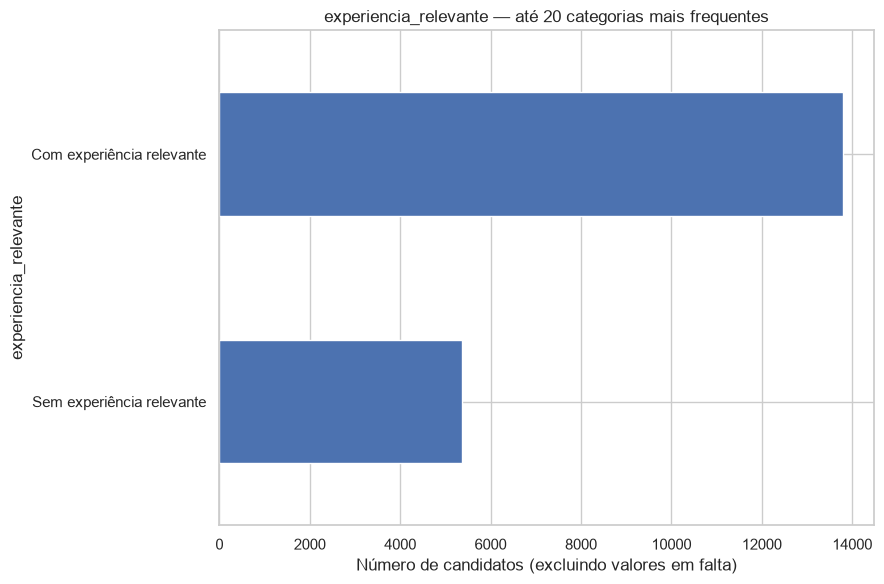

inscricao_universidade: 3 categorias; moda: Não inscrito


,Frequência absoluta,Percentagem (%)
inscricao_universidade,,
Não inscrito,13817,73.60
Curso a tempo inteiro,3757,20.01
Curso a tempo parcial,1198,6.38


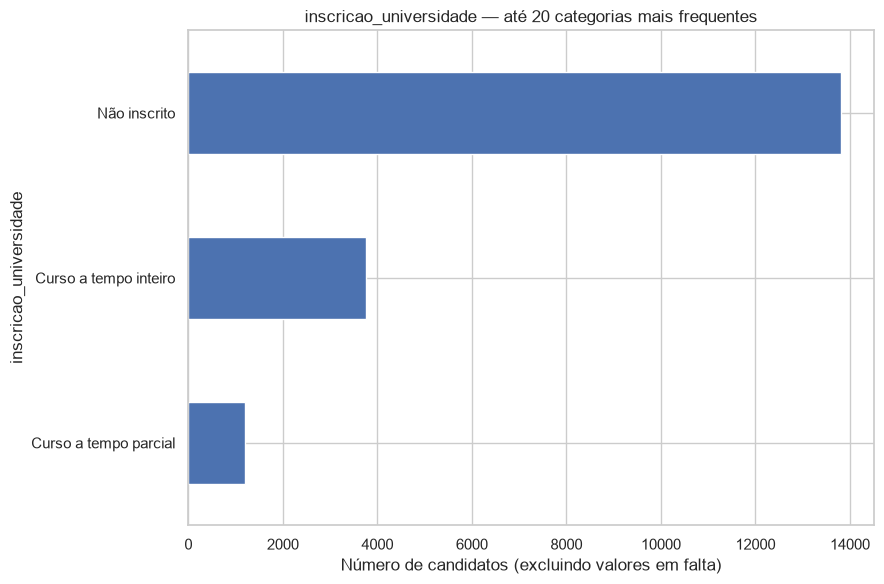

nivel_educacao: 5 categorias; moda: Licenciatura


,Frequência absoluta,Percentagem (%)
nivel_educacao,,
Licenciatura,11598,62.03
Mestrado,4361,23.32
Ensino Secundário,2017,10.79
Doutoramento,414,2.21
Ensino Básico,308,1.65


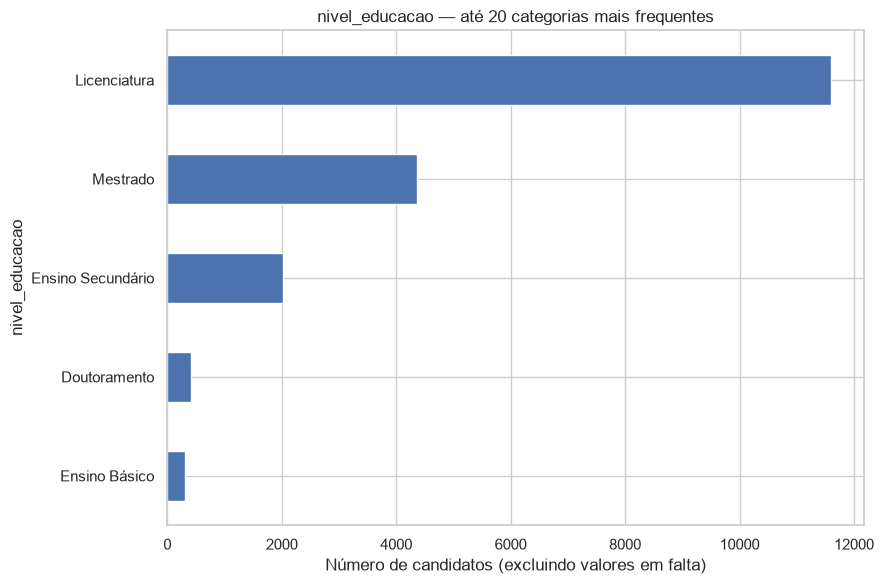

area_formacao: 6 categorias; moda: Ciência, Tecnologia, Engenharia e Matemática


,Frequência absoluta,Percentagem (%)
area_formacao,,
"Ciência, Tecnologia, Engenharia e Matemática",14492,88.66
Humanidades,669,4.09
Outro,381,2.33
Gestão e Negócios,327,2.00
Artes,253,1.55
Sem especialização,223,1.36


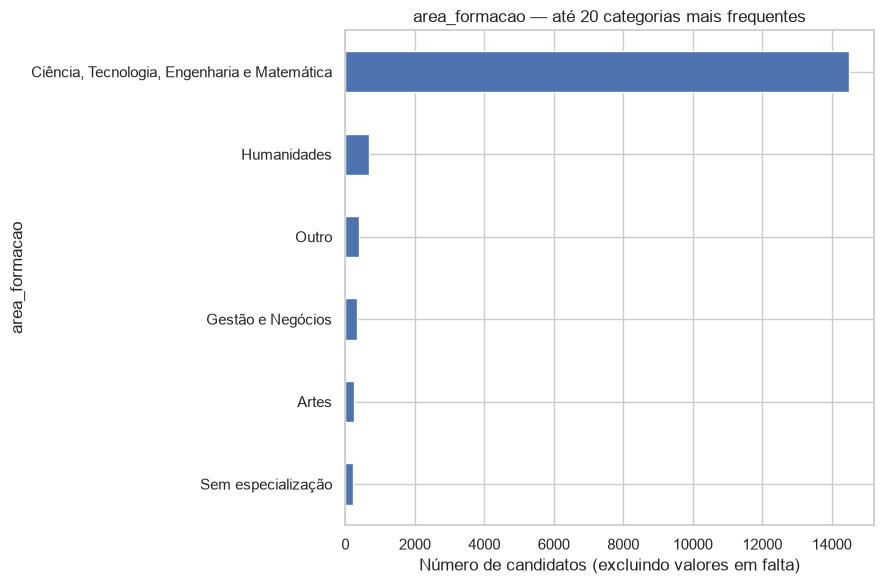

anos_experiencia: 22 categorias; moda: Mais de 20 anos


,Frequência absoluta,Percentagem (%)
anos_experiencia,,
Mais de 20 anos,3286,17.21
5 anos,1430,7.49
4 anos,1403,7.35
3 anos,1354,7.09
6 anos,1216,6.37
2 anos,1127,5.90
7 anos,1028,5.38
10 anos,985,5.16
9 anos,980,5.13


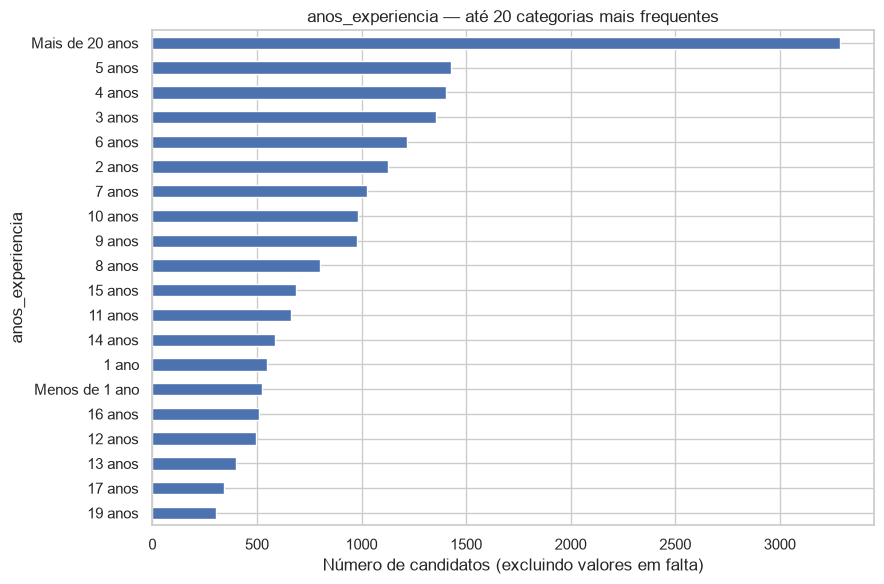

dimensao_empresa: 8 categorias; moda: 50 a 99


,Frequência absoluta,Percentagem (%)
dimensao_empresa,,
50 a 99,3083,23.32
100 a 500,2571,19.45
10000 ou mais,2019,15.27
10 a 49,1471,11.13
1000 a 4999,1328,10.05
Menos de 10,1308,9.89
500 a 999,877,6.63
5000 a 9999,563,4.26


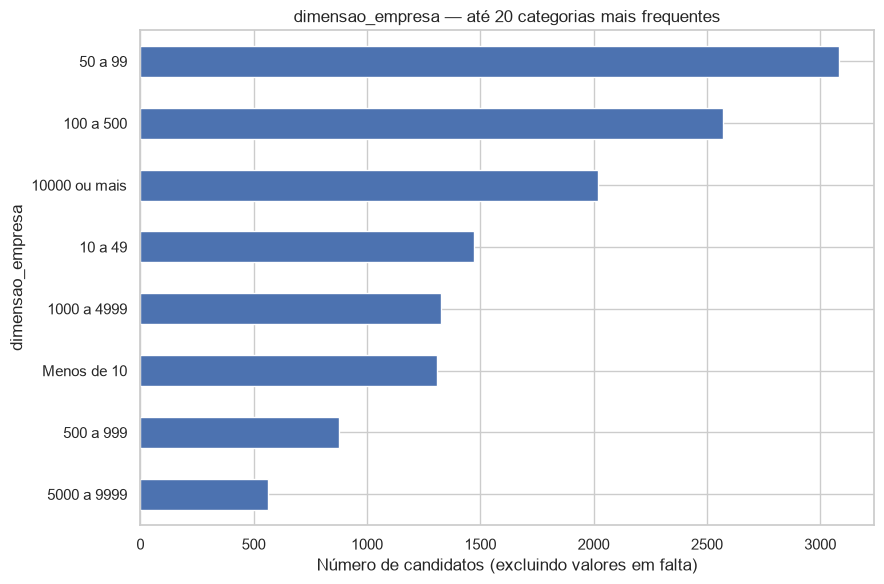

tipo_empresa: 6 categorias; moda: Empresa privada


,Frequência absoluta,Percentagem (%)
tipo_empresa,,
Empresa privada,9817,75.41
Startup financiada,1001,7.69
Setor público,955,7.34
Startup em fase inicial,603,4.63
ONG,521,4.00
Outro,121,0.93


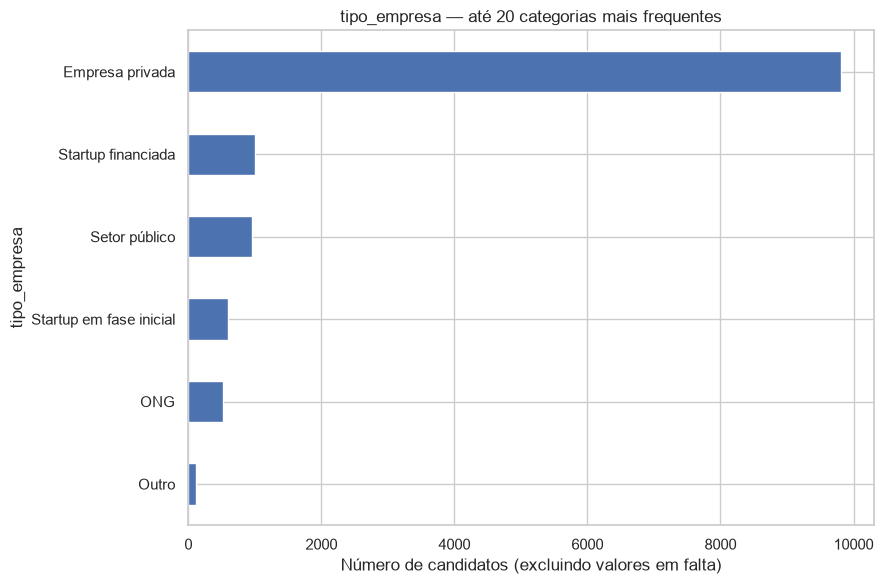

anos_desde_ultimo_emprego: 6 categorias; moda: 1 ano


,Frequência absoluta,Percentagem (%)
anos_desde_ultimo_emprego,,
1 ano,8040,42.91
Mais de 4 anos,3290,17.56
2 anos,2900,15.48
Nunca,2452,13.09
4 anos,1029,5.49
3 anos,1024,5.47


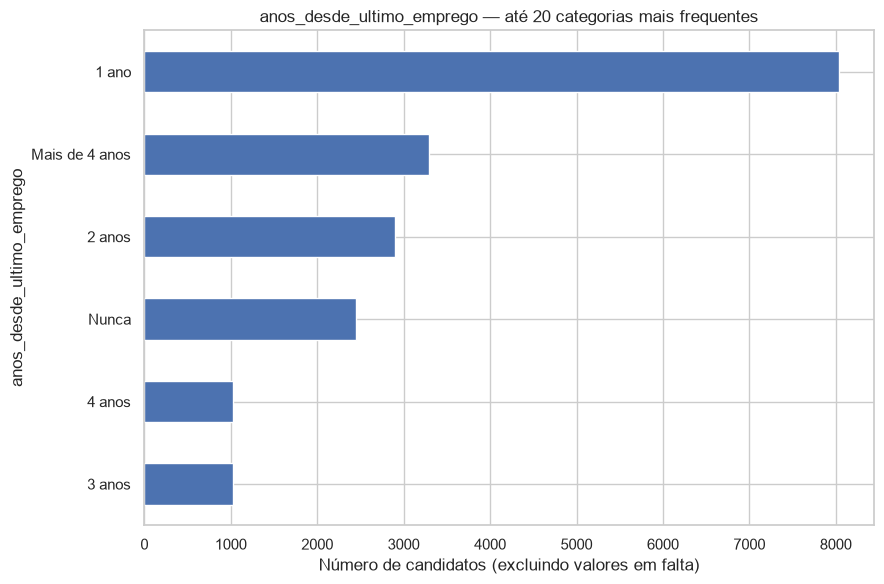

In [22]:
for coluna in cat_cols:
    dados = df[coluna].dropna()
    frequencias = dados.value_counts()
    tabela_frequencias = pd.DataFrame({
        'Frequência absoluta': frequencias,
        'Percentagem (%)': frequencias / len(dados) * 100
    })
    print(f'{coluna}: {dados.nunique()} categorias; moda: {dados.mode().iloc[0]}')
    display(tabela_frequencias.round(2))
    # A tabela contém todas as categorias; o gráfico limita-se às 20 maiores.
    frequencias.head(20).sort_values().plot.barh(figsize=(9, 6))
    plt.title(f'{coluna} — até 20 categorias mais frequentes')
    plt.xlabel('Número de candidatos (excluindo valores em falta)')
    plt.tight_layout()
    plt.show()

##### Análise e Interpretação

> *Há categorias raras ou dominantes? A cardinalidade é alta?*

**Resposta:**


Consideramos **categorias raras** as que representam menos de 1% dos registos e **categorias dominantes** as que representam mais de 50%.

| Variável | Cardinalidade | Categorias raras | Categorias dominantes |
|---|---:|---|---|
| `cidade` | Alta (123) | Sim | Não |
| `genero` | Baixa (3) | Não | Sim — `Masculino` (90,25%) |
| `experiencia_relevante` | Baixa (2) | Não | Sim — `Com experiência relevante` (71,99%) |
| `inscricao_universidade` | Baixa (3) | Não | Sim — `Não inscrito` (73,60%) |
| `nivel_educacao` | Baixa (5) | Não | Sim — `Licenciatura` (62,03%) |
| `area_formacao` | Baixa (6) | Não | Sim — área de Ciência, Tecnologia, Engenharia e Matemática (88,66%) |
| `anos_experiencia` | Moderada (22) | Sim — `20 anos` (0,78%) | Não |
| `dimensao_empresa` | Baixa (8) | Não | Não |
| `tipo_empresa` | Baixa (6) | Sim — `Outro` (0,93%) | Sim — `Empresa privada` (75,41%) |
| `anos_desde_ultimo_emprego` | Baixa (6) | Não | Não |

A variável `cidade` destaca-se pela cardinalidade elevada e pela existência de muitas categorias raras.



**4.8 [Classificação] Balanceamento da variável-alvo**
- `value_counts()` (absoluto e `normalize=True`) e `countplot` do target.

,Frequência absoluta,Percentagem (%)
procura_mudanca_emprego,,
Não,14381,75.07
Sim,4777,24.93


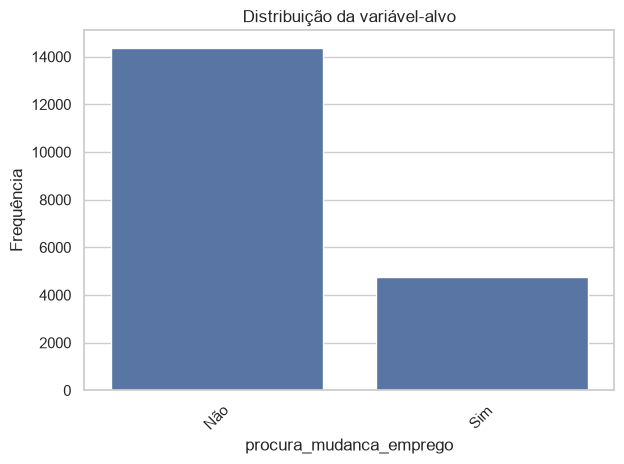

In [23]:
frequencia_target = df[target].value_counts()
percentagem_target = df[target].value_counts(normalize=True) * 100

tabela_target = pd.DataFrame({
    "Frequência absoluta": frequencia_target,
    "Percentagem (%)": percentagem_target.round(2)
})

display(tabela_target)


sns.countplot(
    data=df,
    x=target,
    order=frequencia_target.index
)

plt.title("Distribuição da variável-alvo")
plt.xlabel(target)
plt.ylabel("Frequência")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *As classes estão equilibradas? Que consequências tem isso para a escolha das métricas e para a divisão treino/teste?*

**Resposta:**

As classes estão desequilibradas: `Não` representa 75,07% dos casos e `Sim` representa 24,93%.

Na divisão treino/teste, deve ser utilizado `stratify=y` para manter esta proporção em ambos os conjuntos. Além da accuracy, devem ser avaliadas métricas como precision, recall, F1-score e ROC-AUC, pois a accuracy pode ser enganadora perante este desequilíbrio.

<hr>

<div style="border-left:5px solid #FF5B34;background:#FFF1EC;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#FF5B34;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Classes desbalanceadas</div>Se uma classe for muito maior do que a outra (ex.: 80/20), a <b>accuracy engana</b>: prever sempre a classe maioritária já dá 80%. Nesse caso usar <b>precision, recall, F1 e ROC-AUC</b> e <code>stratify=y</code> na divisão treino/teste. Também determina se são precisas técnicas como <code>class_weight</code> ou reamostragem (SMOTE) — M2.03. A reamostragem (SMOTE, oversampling, undersampling) faz-se <b>só no treino</b> e, na validação cruzada, dentro de cada fold (Pipeline do <code>imblearn</code>). Nunca antes da divisão: exemplos sintéticos criados a partir de linhas do teste passariam informação do teste para o treino. O teste mantém sempre a distribuição real.</div>

### 5. Análise bivariada
<hr>

**Variáveis vs Target**
- Classificação: boxplot/violin por classe, médias por grupo, taxa do target por categoria
- Regressão: scatter plot com o target, correlação com o target, boxplot do target por categoria

**Correlação entre variáveis**
- Matriz de correlação e heatmap
- Identificar multicolinearidade (variáveis explicativas fortemente correlacionadas entre si)

**Testes estatísticos (M2.05)** — intervalos de confiança e testes de hipóteses para confirmar as hipóteses da Fase 1.

***Objetivo:*** perceber as relações importantes.

**5.1 [Classificação] Numéricas por classe do target**
- Boxplot (`showmeans=True`) ou violinplot de cada numérica por classe do target.
- Tabela de médias e medianas por classe (`groupby`).

Tabela de médias e medianas por classe:


,indice_desenvolvimento_cidade_mean,indice_desenvolvimento_cidade_median,horas_formacao_mean,horas_formacao_median
procura_mudanca_emprego,,,,
Não,0.85,0.91,66.11,48.0
Sim,0.76,0.74,63.12,46.0


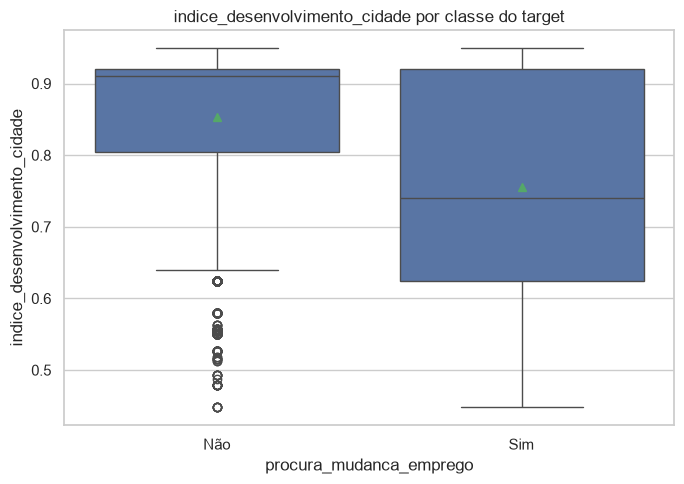

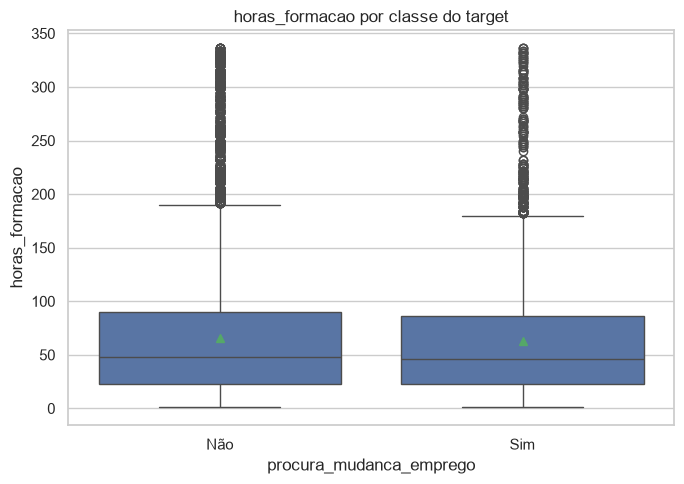

In [24]:
# Tabela de médias e medianas por classe do target
tabela_grupos = df.groupby(target)[num_cols].agg(
    ["mean", "median"]
).round(2)

tabela_grupos.columns = [
    f"{variavel}_{estatistica}"
    for variavel, estatistica in tabela_grupos.columns
]

print("Tabela de médias e medianas por classe:")
display(tabela_grupos)

# Boxplots por classe do target
for coluna in num_cols:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x=target,
        y=coluna,
        showmeans=True
    )

    plt.title(f"{coluna} por classe do target")
    plt.xlabel(target)
    plt.ylabel(coluna)
    plt.tight_layout()
    plt.show()

##### Análise e Interpretação

> *Que variáveis parecem separar melhor as classes?*

**Resposta:**

A variável que melhor separa as classes é `indice_desenvolvimento_cidade`, pois apresenta diferenças maiores entre as médias e medianas dos grupos. As `horas_formacao` têm valores muito semelhantes entre as classes.
<hr>

**5.2 [Classificação] Taxa do target por categoria**
- `pd.crosstab(..., normalize="index")` para cada categórica.
- `countplot` com `hue=TARGET` e `barplot` da taxa média do target por categoria.

Variável: cidade


procura_mudanca_emprego,Não,Sim
cidade,,
Zona_001,0.885,0.115
Zona_002,0.895,0.105
Zona_003,0.764,0.236
Zona_004,0.427,0.573
Zona_005,0.829,0.171
...,...,...
Zona_119,0.808,0.192
Zona_120,0.615,0.385
Zona_121,0.923,0.077


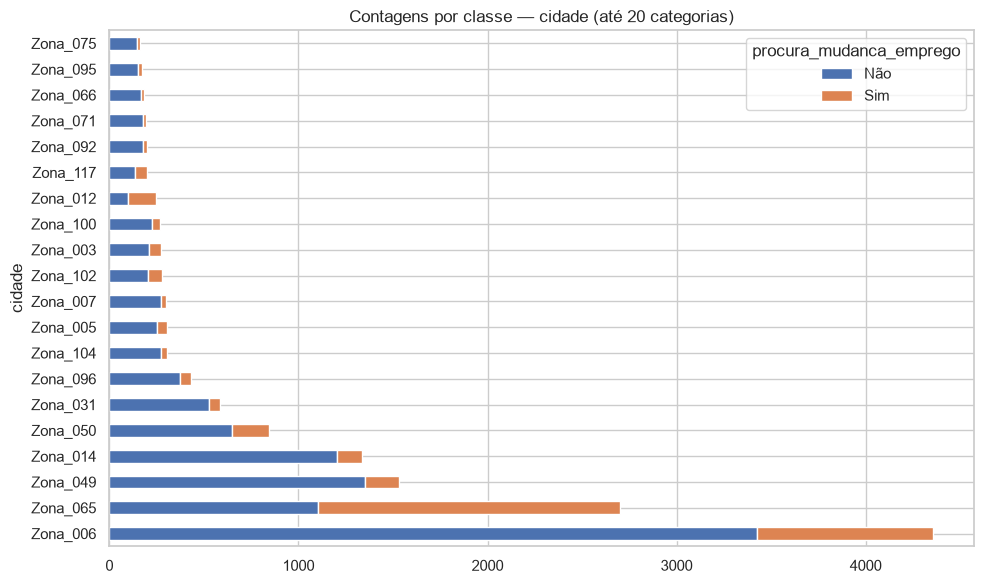

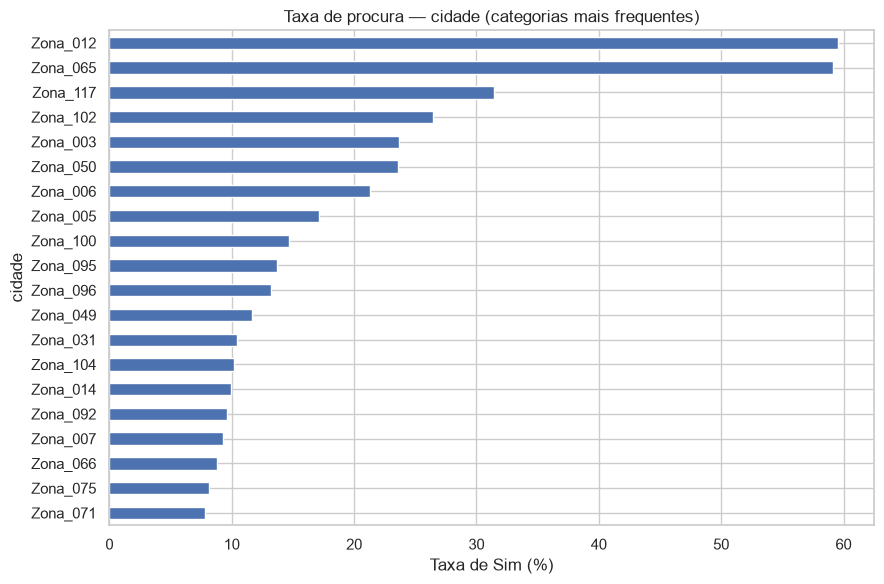

Variável: genero


procura_mudanca_emprego,Não,Sim
genero,,
Feminino,0.737,0.263
Masculino,0.772,0.228
Outro,0.738,0.262


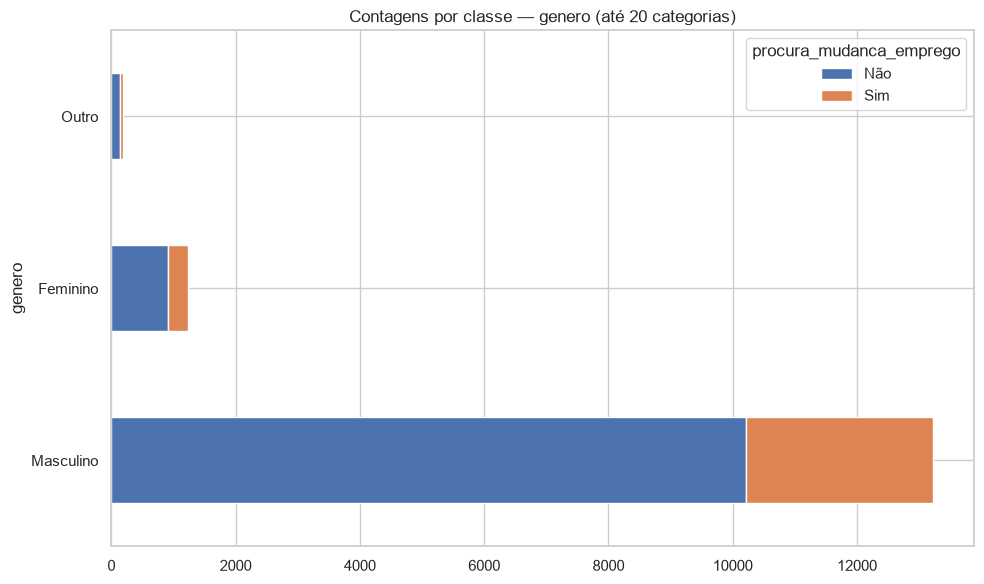

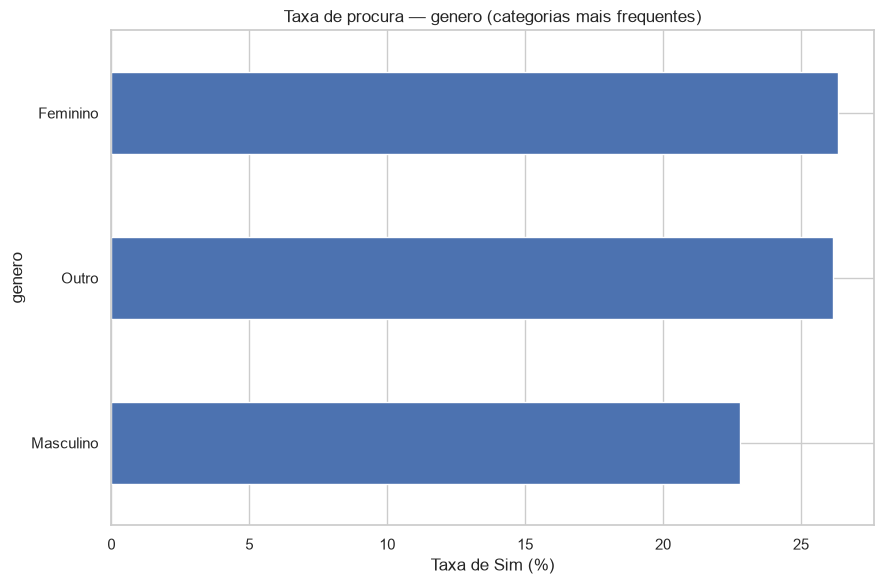

Variável: experiencia_relevante


procura_mudanca_emprego,Não,Sim
experiencia_relevante,,
Com experiência relevante,0.785,0.215
Sem experiência relevante,0.662,0.338


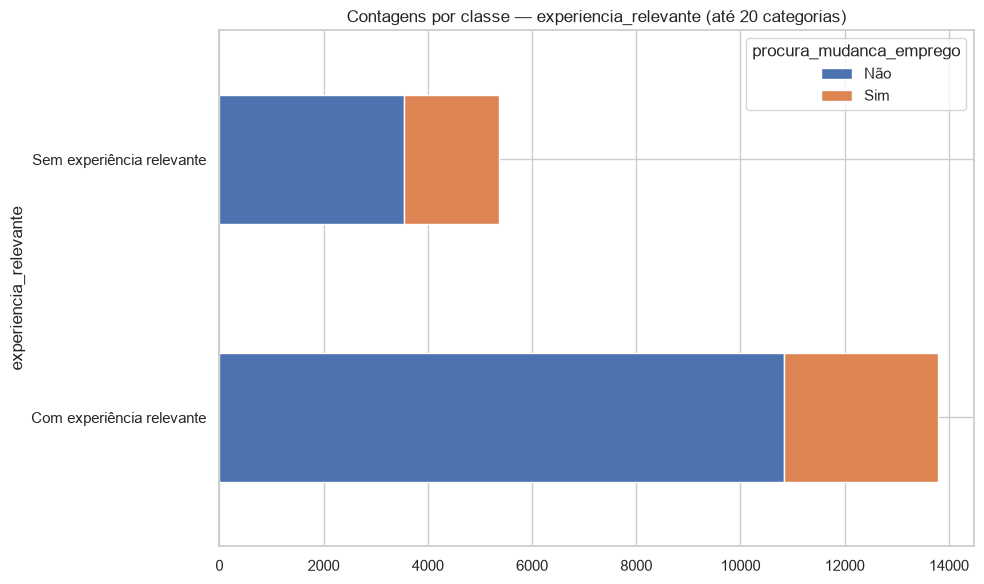

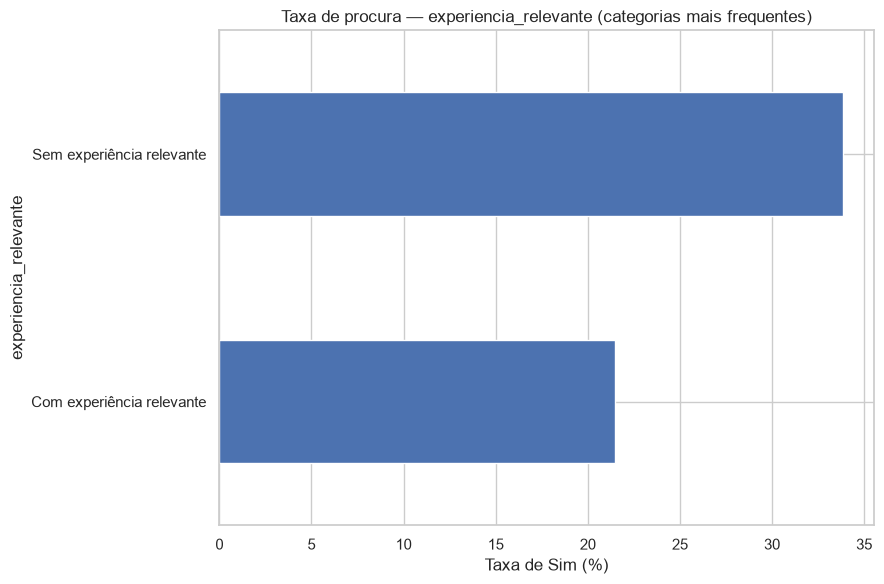

Variável: inscricao_universidade


procura_mudanca_emprego,Não,Sim
inscricao_universidade,,
Curso a tempo inteiro,0.619,0.381
Curso a tempo parcial,0.748,0.252
Não inscrito,0.789,0.211


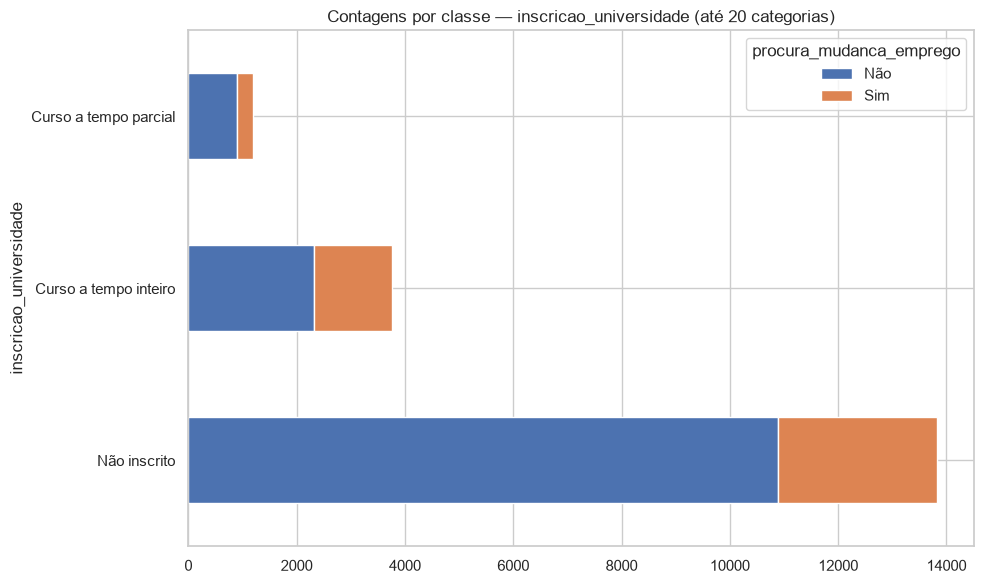

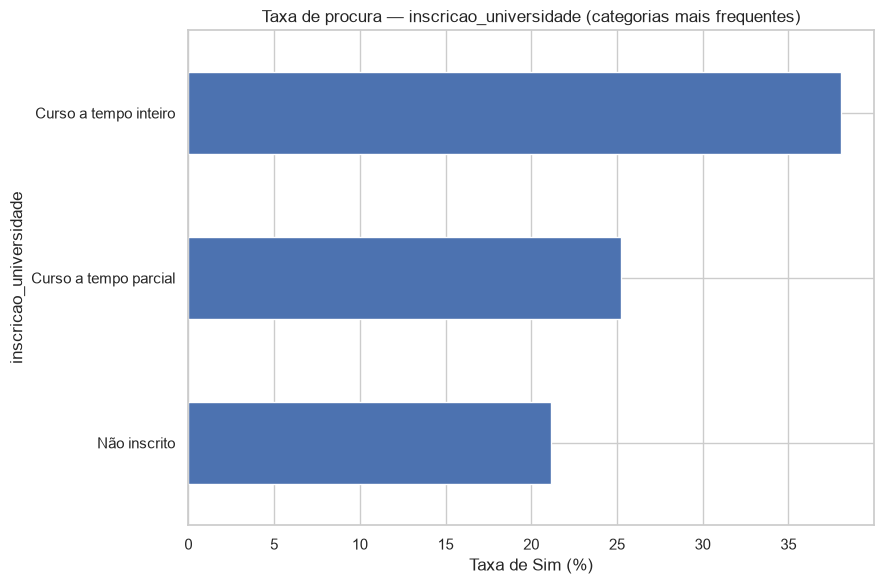

Variável: nivel_educacao


procura_mudanca_emprego,Não,Sim
nivel_educacao,,
Doutoramento,0.860,0.140
Ensino Básico,0.867,0.133
Ensino Secundário,0.805,0.195
Licenciatura,0.720,0.280
Mestrado,0.786,0.214


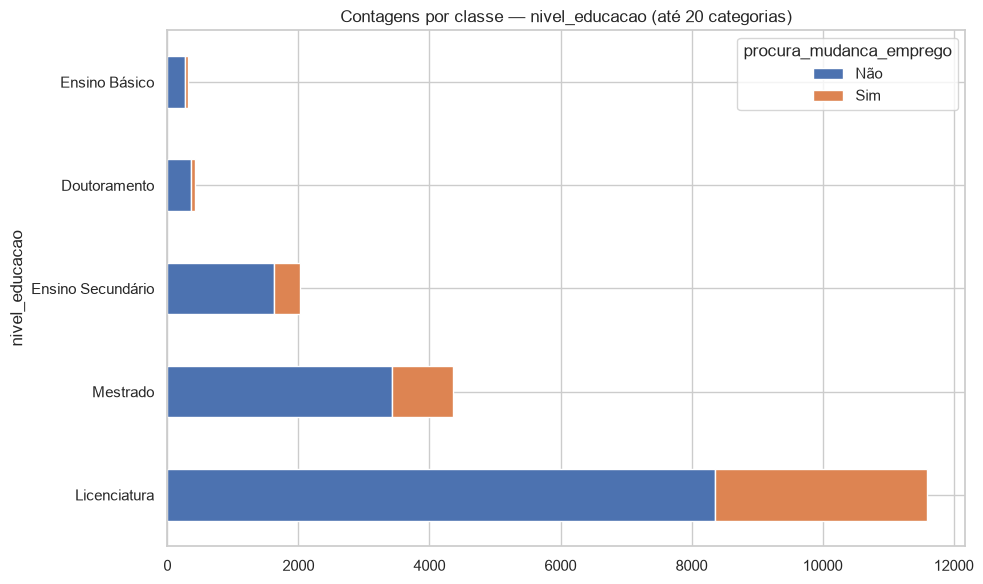

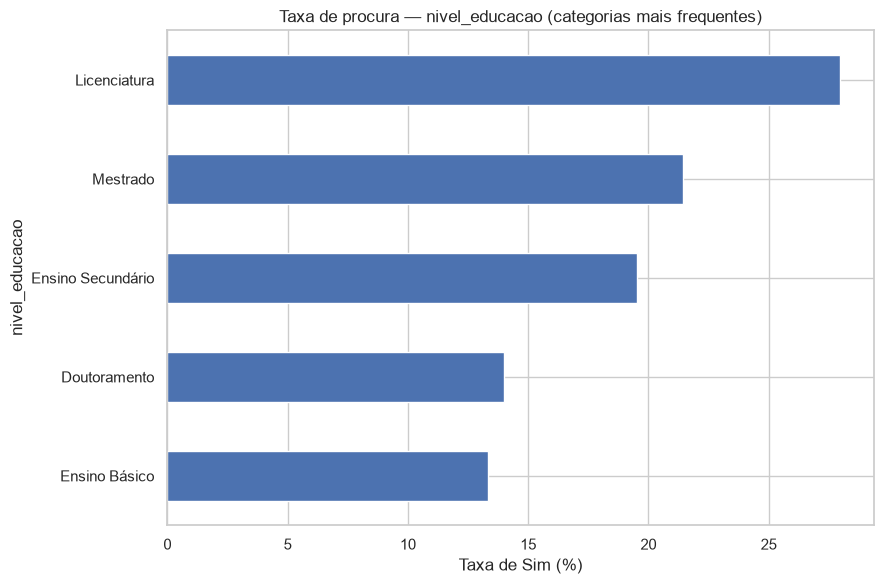

Variável: area_formacao


procura_mudanca_emprego,Não,Sim
area_formacao,,
Artes,0.791,0.209
"Ciência, Tecnologia, Engenharia e Matemática",0.738,0.262
Gestão e Negócios,0.737,0.263
Humanidades,0.789,0.211
Outro,0.732,0.268
Sem especialização,0.753,0.247


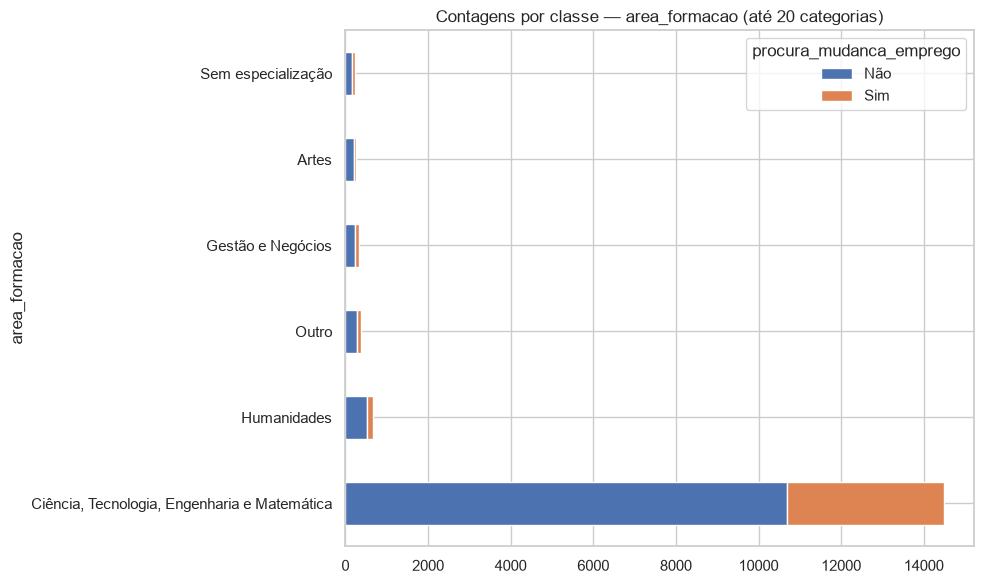

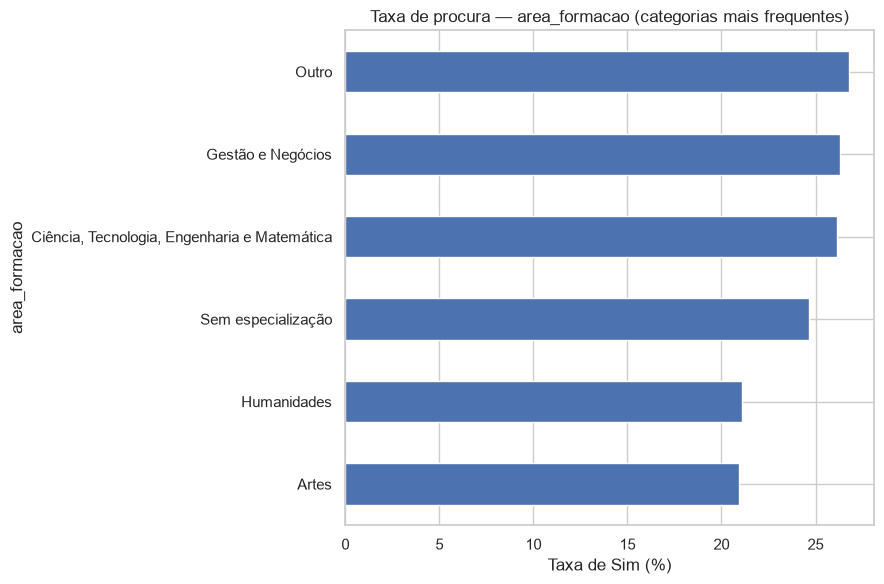

Variável: anos_experiencia


procura_mudanca_emprego,Não,Sim
anos_experiencia,,
1 ano,0.576,0.424
10 anos,0.790,0.210
11 anos,0.773,0.227
12 anos,0.814,0.186
13 anos,0.807,0.193
14 anos,0.817,0.183
15 anos,0.834,0.166
16 anos,0.858,0.142
17 anos,0.833,0.167


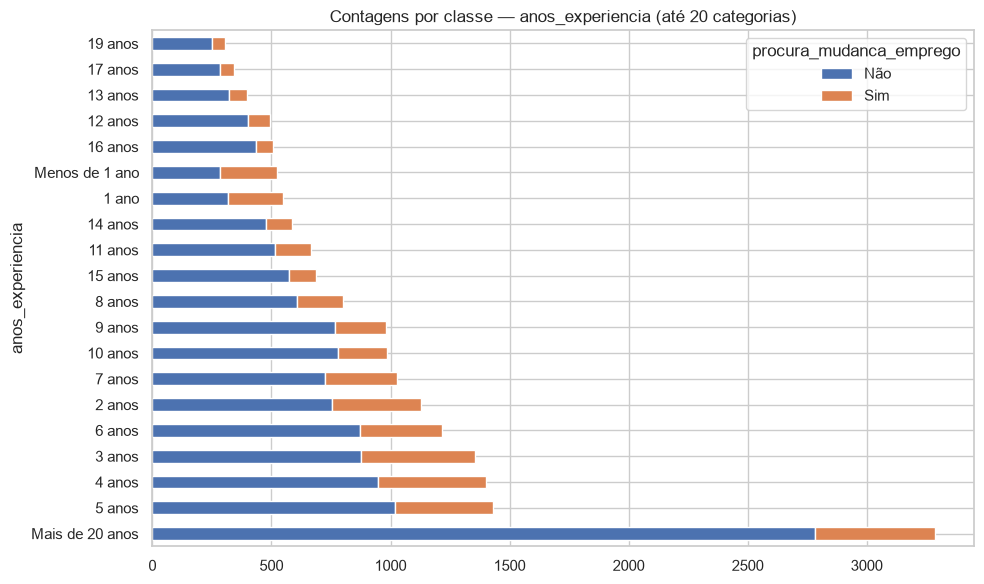

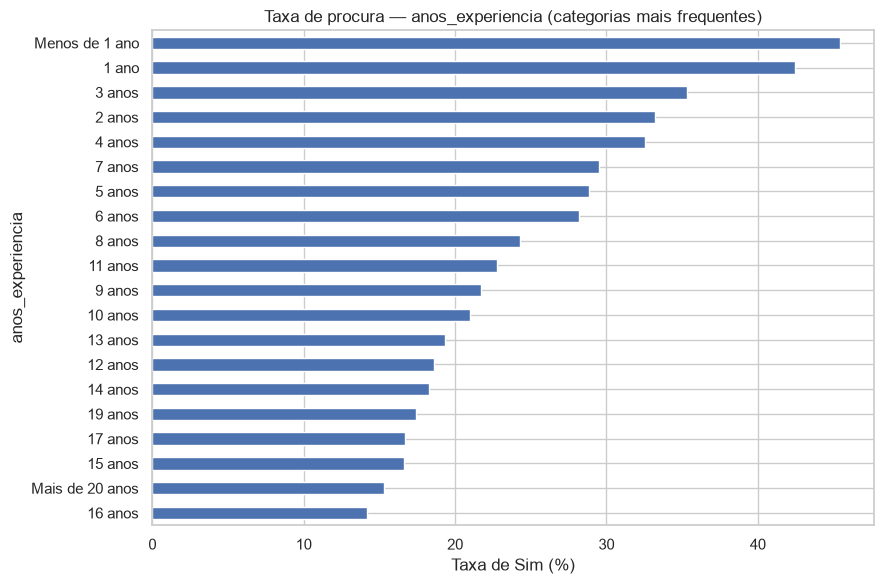

Variável: dimensao_empresa


procura_mudanca_emprego,Não,Sim
dimensao_empresa,,
10 a 49,0.766,0.234
100 a 500,0.839,0.161
1000 a 4999,0.849,0.151
10000 ou mais,0.809,0.191
50 a 99,0.823,0.177
500 a 999,0.827,0.173
5000 a 9999,0.819,0.181
Menos de 10,0.829,0.171


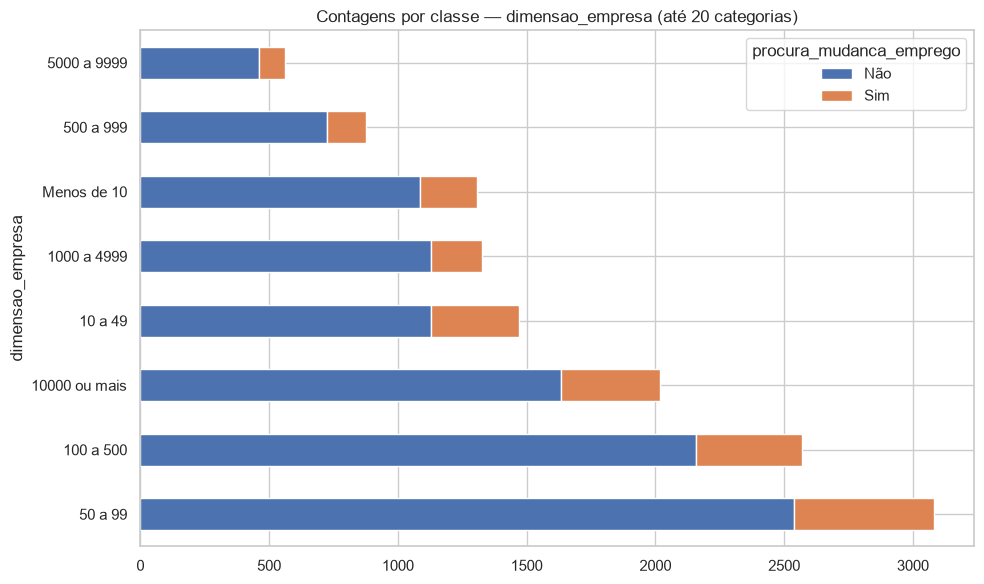

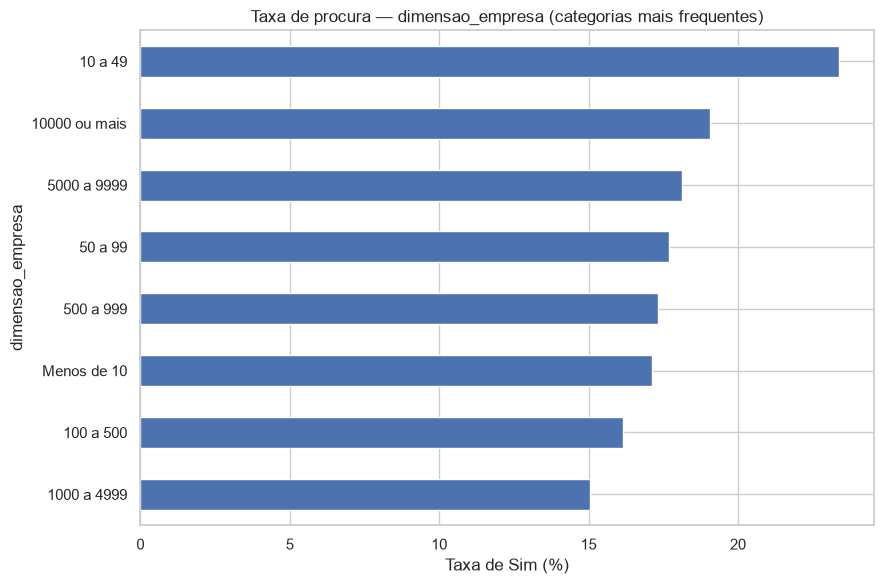

Variável: tipo_empresa


procura_mudanca_emprego,Não,Sim
tipo_empresa,,
Empresa privada,0.819,0.181
ONG,0.814,0.186
Outro,0.760,0.240
Setor público,0.780,0.220
Startup em fase inicial,0.765,0.235
Startup financiada,0.860,0.140


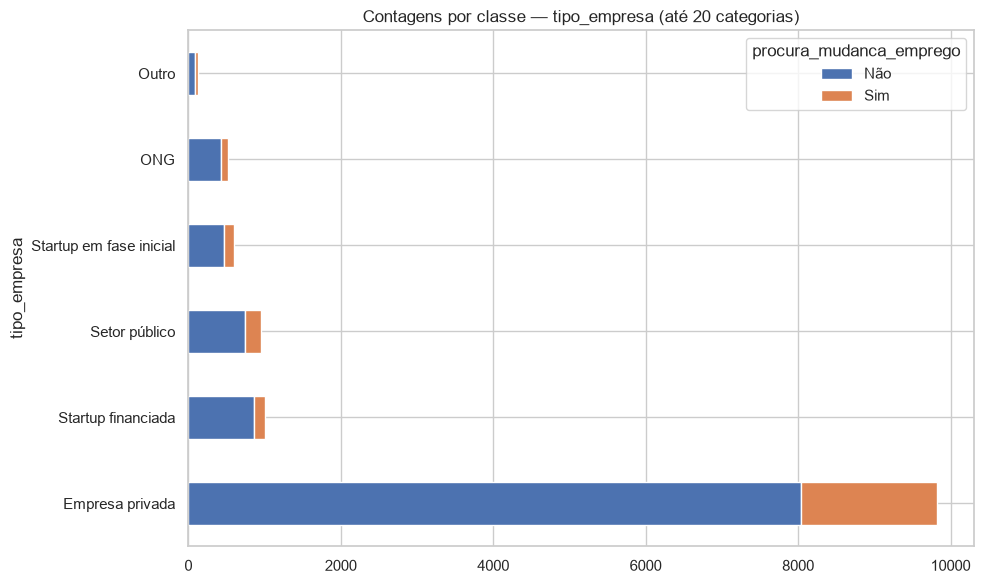

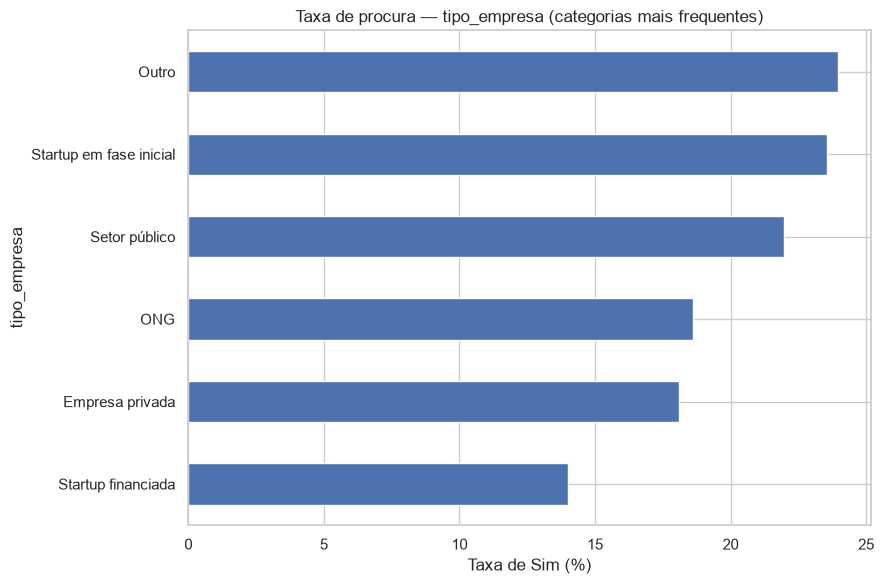

Variável: anos_desde_ultimo_emprego


procura_mudanca_emprego,Não,Sim
anos_desde_ultimo_emprego,,
1 ano,0.736,0.264
2 anos,0.759,0.241
3 anos,0.774,0.226
4 anos,0.778,0.222
Mais de 4 anos,0.818,0.182
Nunca,0.699,0.301


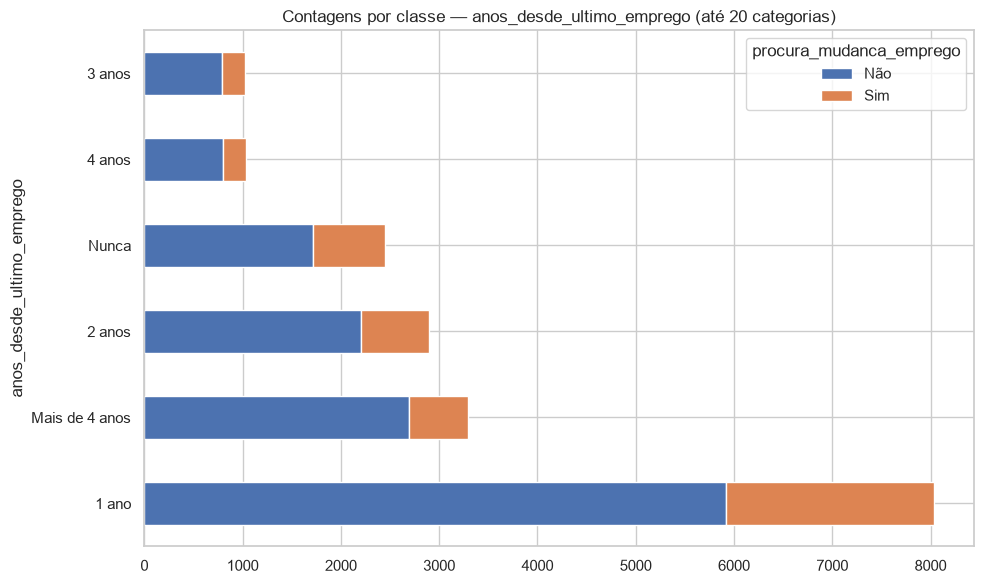

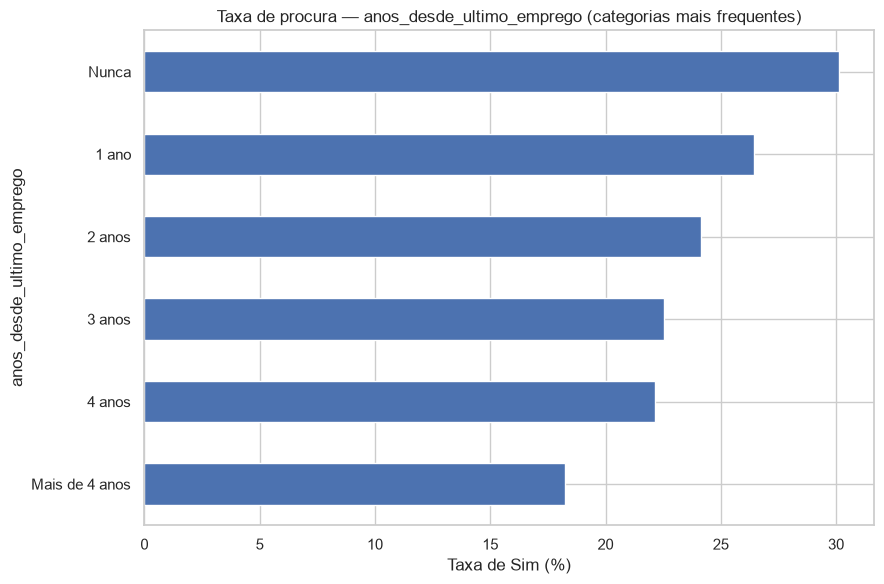

In [25]:
for coluna in cat_cols:
    tabela = pd.crosstab(df[coluna], df[target])
    print(f'Variável: {coluna}')
    display(tabela.div(tabela.sum(axis=1), axis=0).round(3))
    frequentes = df[coluna].value_counts().head(20).index
    tabela.loc[frequentes].plot.barh(stacked=True, figsize=(10, 6))
    plt.title(f'Contagens por classe — {coluna} (até 20 categorias)')
    plt.tight_layout()
    plt.show()
    taxa_target = tabela['Sim'].div(tabela.sum(axis=1)) * 100
    taxa_target.loc[frequentes].sort_values().plot.barh(figsize=(9, 6))
    plt.title(f'Taxa de procura — {coluna} (categorias mais frequentes)')
    plt.xlabel('Taxa de Sim (%)')
    plt.tight_layout()
    plt.show()

##### Análise e Interpretação

> *Que categorias têm taxas muito diferentes? Confirma alguma hipótese da Fase 1?*

**Resposta:**

- **Experiência:** menos de 1 ano apresenta **45,4%**, contra **15,3%** em mais de 20 anos.
- **Experiência relevante:** sem experiência apresenta **33,8%**, contra **21,5%** com experiência.
- **Universidade:** tempo inteiro apresenta **38,1%**, contra **21,1%** entre não inscritos.
- **Educação:** licenciatura apresenta **28,0%**, doutoramento **14,0%** e ensino básico **13,3%**.

**H1** e **H2** são apoiadas pelos padrões e testes da secção 5.5. A H2 exige associação, não uma relação linear. **H3** não é apoiada: a associação com desenvolvimento é negativa. Os resultados não estabelecem causalidade.

<hr>

**5.1 Associação das numéricas com o alvo binário (análise complementar)**

O problema é de classificação. As correlações e a reta servem apenas para exploração; a reta não estima probabilidades válidas em todo o intervalo.

,variavel,pearson,p_value_pearson,spearman,p_value_spearman
0,indice_desenvolvimento_cidade,-0.3417,0.0000,-0.2792,0.0000
1,horas_formacao,-0.0216,0.0028,-0.0141,0.0506


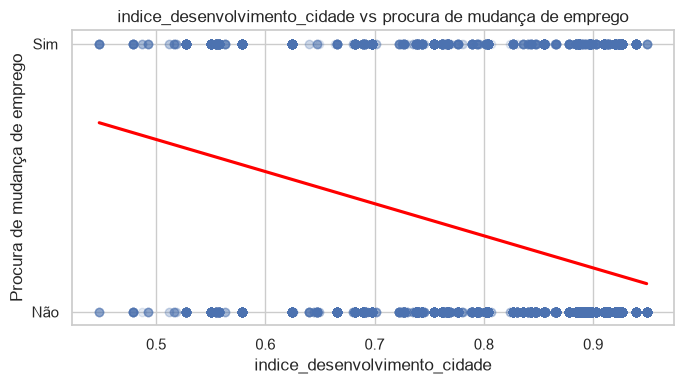

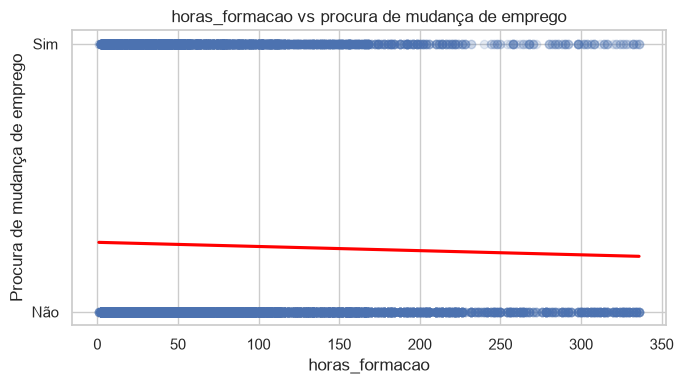

In [26]:
# 5.1 Regressão: variáveis numéricas vs target

from scipy.stats import pearsonr, spearmanr

# Criar uma cópia dos dados
df_analise = df.copy()

# Codificar o target: Sim = 1; Não = 0
df_analise["target_binario"] = (
    df_analise["procura_mudanca_emprego"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"sim": 1, "não": 0})
)


variaveis_numericas = num_cols

# Calcular correlações
resultados_correlacao = []

for coluna in variaveis_numericas:
    dados = df_analise[[coluna, "target_binario"]].dropna()

    correlacao_pearson, p_pearson = pearsonr(
        dados[coluna],
        dados["target_binario"]
    )

    correlacao_spearman, p_spearman = spearmanr(
        dados[coluna],
        dados["target_binario"]
    )

    resultados_correlacao.append({
        "variavel": coluna,
        "pearson": correlacao_pearson,
        "p_value_pearson": p_pearson,
        "spearman": correlacao_spearman,
        "p_value_spearman": p_spearman
    })

# Criar tabela final
tabela_correlacoes = pd.DataFrame(resultados_correlacao)

tabela_correlacoes = (
    tabela_correlacoes
    .sort_values("pearson", key=abs, ascending=False)
    .reset_index(drop=True)
)

display(tabela_correlacoes.round(4))


# Gráficos de dispersão com linha de tendência

for coluna in variaveis_numericas:
    plt.figure(figsize=(7, 4))

    sns.regplot(
        data=df_analise,
        x=coluna,
        y="target_binario",
        logistic=False,
        ci=None,
        scatter_kws={"alpha": 0.15},
        line_kws={"color": "red"}
    )

    plt.title(f"{coluna} vs procura de mudança de emprego")
    plt.xlabel(coluna)
    plt.ylabel("Procura de mudança de emprego")
    plt.yticks([0, 1], ["Não", "Sim"])
    plt.tight_layout()
    plt.show()

##### Análise e Interpretação

> *Que variáveis têm relação mais forte com o alvo? A relação é linear?*

**Resposta:**

- `indice_desenvolvimento_cidade` apresenta a associação mais forte com o alvo (Pearson = **−0,34**; Spearman = **−0,28**): maior desenvolvimento associa-se a menor procura de mudança.
- `horas_formacao` tem associação praticamente nula (Pearson = **−0,02**; Spearman = **−0,01**).
- Estes coeficientes não demonstram linearidade nem causalidade. A reta é uma tendência exploratória para um alvo binário.

<hr>

**5.2 Resumo do alvo binário por categoria (análise complementar)**

A média de 0/1 representa a taxa de procura de mudança. Apresentam-se contagem, média e mediana; para este alvo, um gráfico de taxas é mais informativo que um boxplot.

Variável: cidade (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
cidade,,,,
Zona_055,1,1.000,1.0,100.000
Zona_033,5,0.800,1.0,80.000
Zona_045,14,0.786,1.0,78.571
Zona_080,13,0.692,1.0,69.231
Zona_010,6,0.667,1.0,66.667
...,...,...,...,...
Zona_063,7,0.000,0.0,0.000
Zona_077,11,0.000,0.0,0.000
Zona_093,5,0.000,0.0,0.000


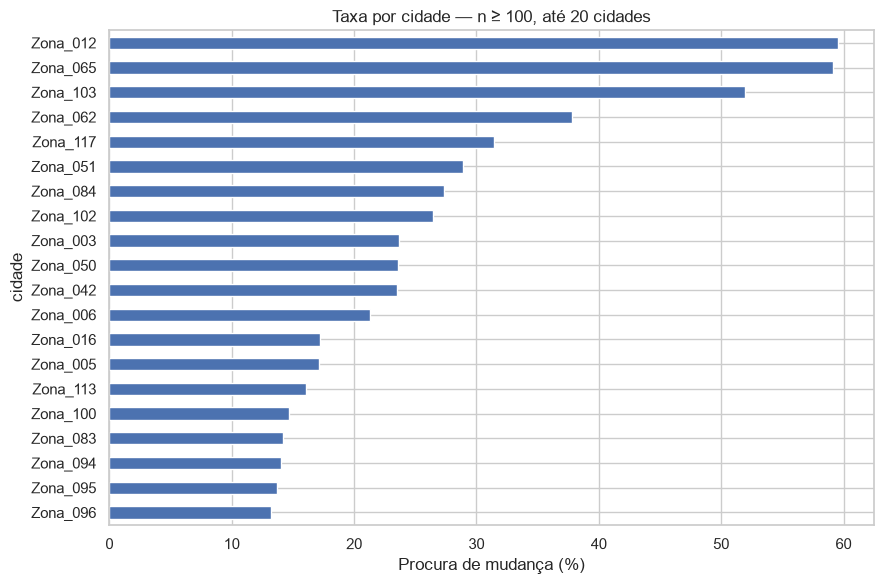

Variável: genero (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
genero,,,,
Feminino,1238,0.263,0.0,26.333
Outro,191,0.262,0.0,26.178
Masculino,13221,0.228,0.0,22.782


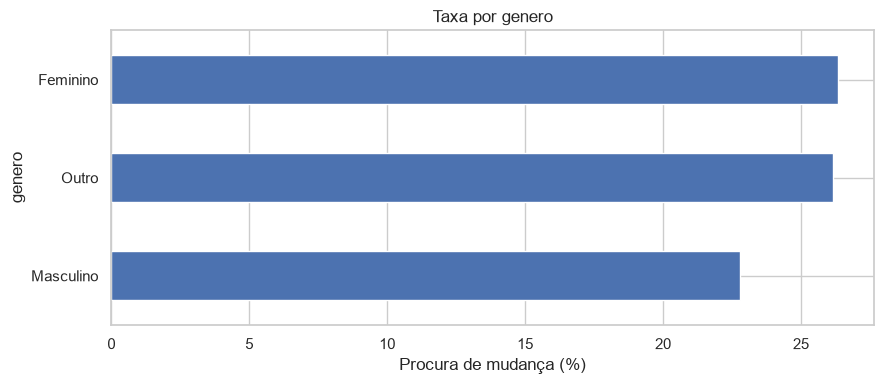

Variável: experiencia_relevante (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
experiencia_relevante,,,,
Sem experiência relevante,5366,0.338,0.0,33.843
Com experiência relevante,13792,0.215,0.0,21.469


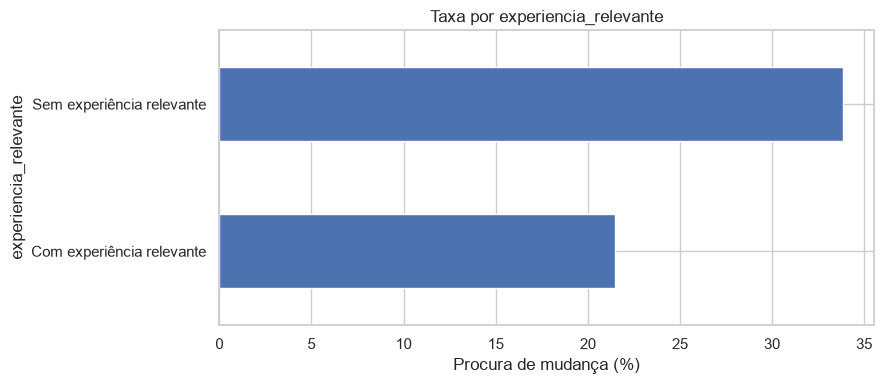

Variável: inscricao_universidade (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
inscricao_universidade,,,,
Curso a tempo inteiro,3757,0.381,0.0,38.089
Curso a tempo parcial,1198,0.252,0.0,25.209
Não inscrito,13817,0.211,0.0,21.141


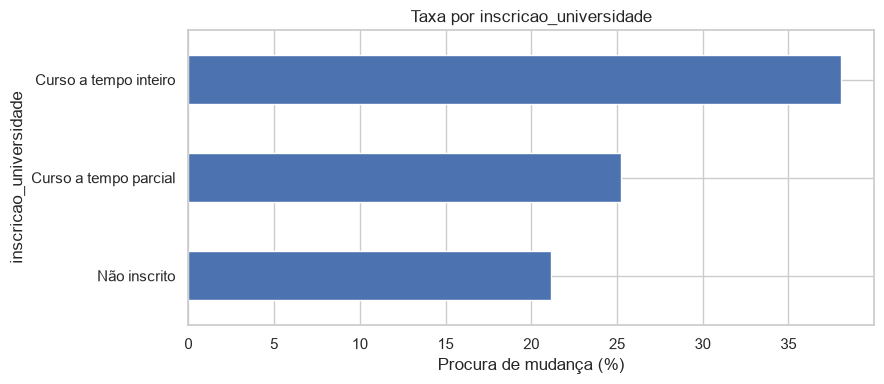

Variável: nivel_educacao (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
nivel_educacao,,,,
Licenciatura,11598,0.280,0.0,27.979
Mestrado,4361,0.214,0.0,21.440
Ensino Secundário,2017,0.195,0.0,19.534
Doutoramento,414,0.140,0.0,14.010
Ensino Básico,308,0.133,0.0,13.312


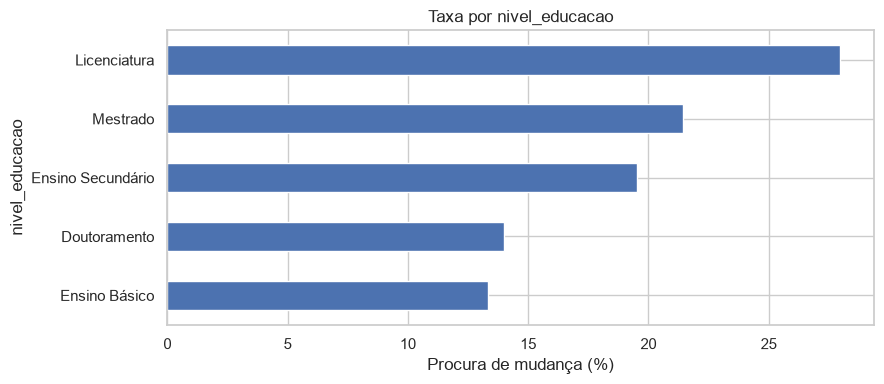

Variável: area_formacao (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
area_formacao,,,,
Outro,381,0.268,0.0,26.772
Gestão e Negócios,327,0.263,0.0,26.300
"Ciência, Tecnologia, Engenharia e Matemática",14492,0.262,0.0,26.159
Sem especialização,223,0.247,0.0,24.664
Humanidades,669,0.211,0.0,21.076
Artes,253,0.209,0.0,20.949


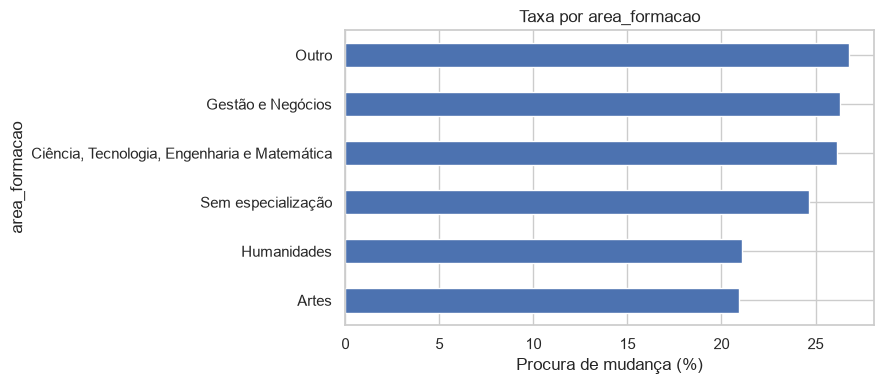

Variável: anos_experiencia (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
anos_experiencia,,,,
Menos de 1 ano,522,0.454,0.0,45.402
1 ano,549,0.424,0.0,42.441
3 anos,1354,0.353,0.0,35.303
2 anos,1127,0.332,0.0,33.185
4 anos,1403,0.326,0.0,32.573
7 anos,1028,0.295,0.0,29.475
5 anos,1430,0.288,0.0,28.811
6 anos,1216,0.282,0.0,28.207
8 anos,802,0.243,0.0,24.314


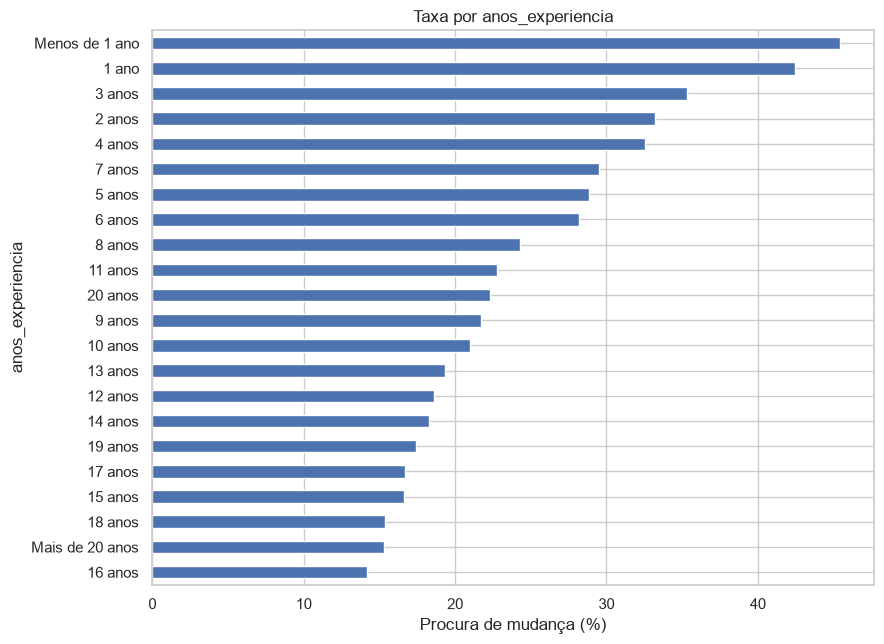

Variável: dimensao_empresa (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
dimensao_empresa,,,,
10 a 49,1471,0.234,0.0,23.385
10000 ou mais,2019,0.191,0.0,19.069
5000 a 9999,563,0.181,0.0,18.117
50 a 99,3083,0.177,0.0,17.678
500 a 999,877,0.173,0.0,17.332
Menos de 10,1308,0.171,0.0,17.125
100 a 500,2571,0.161,0.0,16.142
1000 a 4999,1328,0.151,0.0,15.060


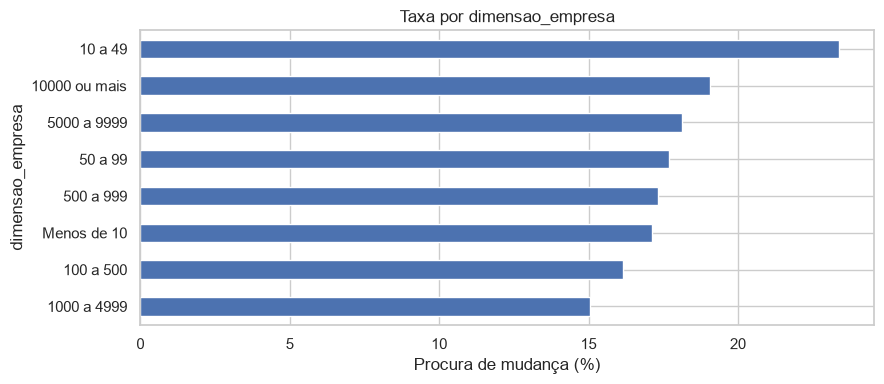

Variável: tipo_empresa (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
tipo_empresa,,,,
Outro,121,0.240,0.0,23.967
Startup em fase inicial,603,0.235,0.0,23.549
Setor público,955,0.220,0.0,21.990
ONG,521,0.186,0.0,18.618
Empresa privada,9817,0.181,0.0,18.081
Startup financiada,1001,0.140,0.0,13.986


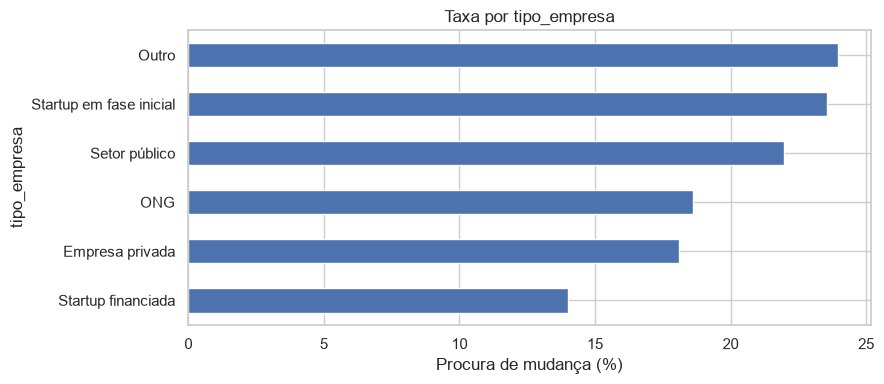

Variável: anos_desde_ultimo_emprego (excluem-se categorias ausentes)


,contagem,media,mediana,taxa_sim_%
anos_desde_ultimo_emprego,,,,
Nunca,2452,0.301,0.0,30.139
1 ano,8040,0.264,0.0,26.430
2 anos,2900,0.241,0.0,24.138
3 anos,1024,0.226,0.0,22.559
4 anos,1029,0.222,0.0,22.157
Mais de 4 anos,3290,0.182,0.0,18.237


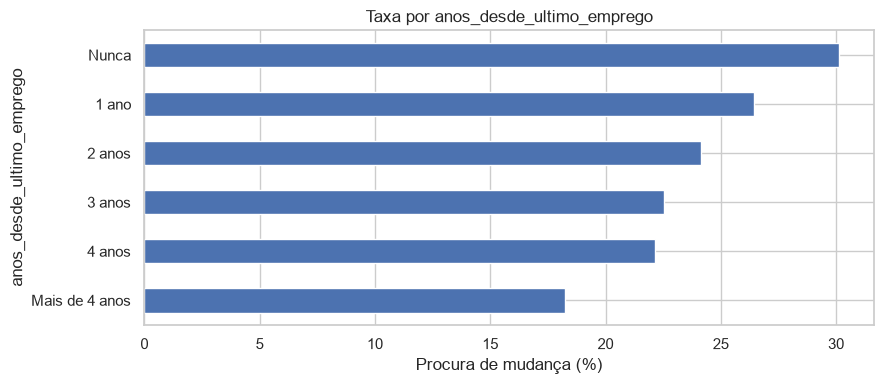

In [27]:
df_categorias = df.copy()
df_categorias['target_binario'] = df[target].astype('string').str.strip().str.lower().map({'sim': 1, 'não': 0})
for coluna in cat_cols:
    tabela = df_categorias.groupby(coluna)['target_binario'].agg(contagem='count', media='mean', mediana='median')
    tabela['taxa_sim_%'] = tabela['media'] * 100
    tabela = tabela.sort_values('media', ascending=False)
    print(f'Variável: {coluna} (excluem-se categorias ausentes)')
    display(tabela.round(3))
    # Cidades: limitar a visualização e evitar destacar grupos muito pequenos.
    grafico = tabela.loc[tabela['contagem'] >= 100].head(20) if coluna == 'cidade' else tabela
    grafico['taxa_sim_%'].sort_values().plot.barh(figsize=(9, max(4, len(grafico) * 0.3)))
    plt.xlabel('Procura de mudança (%)')
    plt.title(f'Taxa por {coluna}' + (' — n ≥ 100, até 20 cidades' if coluna == 'cidade' else ''))
    plt.tight_layout()
    plt.show()

##### Análise e Interpretação

> *O valor do alvo muda muito entre categorias?*

**Resposta:**

- **Experiência:** menos de 1 ano apresenta **45,4%**, contra **15,3%** em mais de 20 anos.
- **Experiência relevante:** sem experiência apresenta **33,8%**, contra **21,5%** com experiência.
- **Universidade:** tempo inteiro apresenta **38,1%**, contra **21,1%** entre não inscritos.
- **Educação:** licenciatura apresenta **28,0%**, doutoramento **14,0%** e ensino básico **13,3%**.

Como observado na secção 5.0, confirma-se que candidatos com menos experiência, sem experiência relevante e inscritos a tempo inteiro apresentam maior procura de mudança de emprego. Estes resultados reforçam a **H1** e apoiam a existência de associação na **H2**.

A média do alvo binário representa a taxa de procura de mudança; a mediana é menos informativa neste caso. As categorias com poucos registos devem ser interpretadas com cautela.

<hr>

**5.3 Matriz de correlação**
- Heatmap da matriz de correlação das numéricas (e do target, se for numérico) com `annot=True`.

,indice_desenvolvimento_cidade,horas_formacao,target_binario
indice_desenvolvimento_cidade,1.0000,0.0019,-0.3417
horas_formacao,0.0019,1.0000,-0.0216
target_binario,-0.3417,-0.0216,1.0000


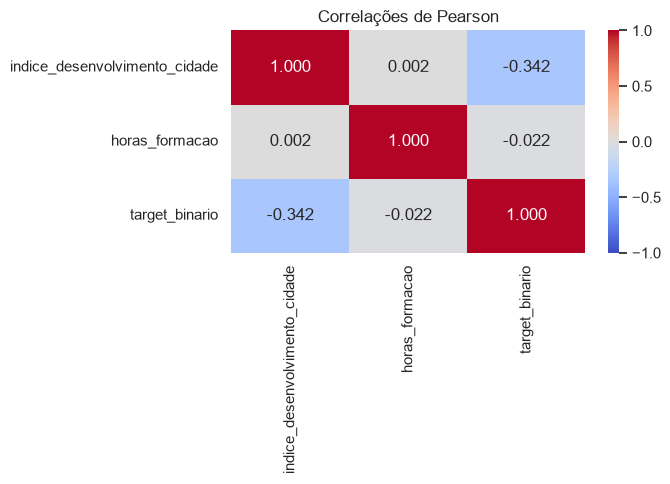

In [28]:
dados_correlacao = df[num_cols].copy()
dados_correlacao['target_binario'] = df_categorias['target_binario']

matriz_correlacao = dados_correlacao.corr(method='pearson')
display(matriz_correlacao.round(4))

plt.figure(figsize=(7, 5))
sns.heatmap(matriz_correlacao, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlações de Pearson')
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Que variáveis estão mais correlacionadas com o alvo? E entre si?*

**Resposta:**

O índice de desenvolvimento apresenta a maior correlação com o alvo (**−0,342**).
As horas de formação apresentam correlação quase nula (**−0,022**). 
Entre as duas variáveis explicativas, a correlação é praticamente zero (**0,002**).

<hr>

**5.4 Multicolinearidade**
- Listar os pares de variáveis explicativas com |r| > 0,8.

In [29]:
cor_explicativas = df[num_cols].corr()
pares = [
    {'variavel_1': a, 'variavel_2': b, 'correlacao': cor_explicativas.loc[a, b]}
    for i, a in enumerate(num_cols) for b in num_cols[i + 1:]
    if abs(cor_explicativas.loc[a, b]) > 0.8
]
tabela_redundancia = pd.DataFrame(pares, columns=['variavel_1', 'variavel_2', 'correlacao'])
display(tabela_redundancia)
print(f'Pares com |r| > 0,8: {len(pares)}')

,variavel_1,variavel_2,correlacao


Pares com |r| > 0,8: 0


##### Análise e Interpretação

> *Há variáveis redundantes? Qual manteriam e porquê?*

**Resposta:**

Não existem pares de numéricas explicativas com **|r| > 0,8**. Não há evidência de redundância linear entre elas; ambas podem ser mantidas nesta fase. Esta análise não avalia redundância entre variáveis categóricas.

<hr>

<div style="border-left:5px solid #0A2540;background:#F5F7FA;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#0A2540;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Visto nas aulas</div>Correlação usa-se de forma <b>crítica</b>: mede apenas relação <b>linear</b> (Pearson) ou monótona (Spearman), é sensível a outliers e <b>correlação não implica causalidade</b>.</div>

#### 5.5 Testes estatísticos (opcional, valorizado)

| Situação | Teste | Hipótese nula (H0) |
|---|---|---|
| Numérica vs target binário | teste t (Welch) / Mann-Whitney | as médias/distribuições são iguais nas duas classes |
| Numérica vs target com 3+ classes | ANOVA / Kruskal-Wallis | as médias são iguais em todos os grupos |
| Categórica vs target categórico | Qui-quadrado | as variáveis são independentes |
| Categórica vs target numérico | teste t (2 grupos) / ANOVA (3+ grupos) | a média do target é igual em todos os grupos |
| Numérica vs target numérico | correlação de Pearson / Spearman (secção 5.1) | — |

Regra de decisão: se **p-value < 0,05**, rejeita-se H0 (a diferença/relação é estatisticamente significativa).

Cuidados (M2.05): o t-test pressupõe normalidade (ou n grande) → usar `equal_var=False` (Welch); a ANOVA diz que *pelo menos um* grupo difere, mas não qual; o qui-quadrado exige frequências esperadas ≥ 5. Alternativas não paramétricas: **Mann-Whitney**, **Kruskal-Wallis**, **Spearman**.

**5.5.1 [Classificação] Intervalos de confiança (M2.05)**
- Para cada numérica e cada classe: n, média e IC 95% (`stats.t.interval` com `stats.sem`).

In [30]:
intervalos = []
for coluna in num_cols:
    for classe, grupo in df.groupby(target):
        valores = grupo[coluna].dropna()
        inferior, superior = stats.t.interval(0.95, len(valores) - 1, loc=valores.mean(), scale=stats.sem(valores))
        intervalos.append({'variavel': coluna, 'classe': classe, 'n': len(valores), 'media': valores.mean(), 'IC95_inferior': inferior, 'IC95_superior': superior})
tabela_ic = pd.DataFrame(intervalos)
display(tabela_ic.round(4))

,variavel,classe,n,media,IC95_inferior,IC95_superior
0,indice_desenvolvimento_cidade,Não,14381,0.8531,0.8514,0.8549
1,indice_desenvolvimento_cidade,Sim,4777,0.7557,0.7517,0.7598
2,horas_formacao,Não,14381,66.1138,65.1177,67.1098
3,horas_formacao,Sim,4777,63.1185,61.4939,64.7430


##### Análise e Interpretação

> *Os intervalos das classes sobrepõem-se? O que isso sugere?*

**Resposta:**

Os IC de 95% das médias não se sobrepõem: desenvolvimento da cidade — **Não: [0,851; 0,855]**, **Sim: [0,752; 0,760]**; horas — **Não: [65,12; 67,11]**, **Sim: [61,49; 64,74]**. Sugerem diferenças entre médias, mais expressivas no desenvolvimento da cidade. São intervalos para as médias, não para os valores individuais.

<hr>

**5.5.2 [Classificação] Testes de diferença de médias (M2.05)**
- 2 classes: `stats.ttest_ind(..., equal_var=False)`; 3+ classes: `stats.f_oneway`.
- Tabela com estatística, p-value e conclusão (α = 0,05).

In [31]:
testes_medias = []
classes = sorted(df[target].dropna().unique())
for coluna in num_cols:
    a, b = [df.loc[df[target] == classe, coluna].dropna() for classe in classes]
    teste = stats.ttest_ind(a, b, equal_var=False)
    mw = stats.mannwhitneyu(a, b, alternative='two-sided')
    desvio_combinado = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
    testes_medias.append({'variavel': coluna, 't_Welch': teste.statistic, 'p_Welch': teste.pvalue, 'p_Mann_Whitney': mw.pvalue, 'd_Cohen': (a.mean()-b.mean())/desvio_combinado})
tabela_testes = pd.DataFrame(testes_medias)
display(tabela_testes.style.format({'t_Welch': '{:.3f}', 'p_Welch': '{:.3e}', 'p_Mann_Whitney': '{:.3e}', 'd_Cohen': '{:.3f}'}))

,variavel,t_Welch,p_Welch,p_Mann_Whitney,d_Cohen
0,indice_desenvolvimento_cidade,43.298,0.000e+00,0.000e+00,0.840
1,horas_formacao,3.081,2.067e-03,5.056e-02,0.050


##### Análise e Interpretação

> *Em que variáveis a diferença entre classes é estatisticamente significativa? Os pressupostos do teste verificam-se?*

**Resposta:**

Welch identifica diferenças de médias em ambas as variáveis (**p < 0,05**). No índice de desenvolvimento, a diferença é expressiva (**d ≈ 0,84**); nas horas, é de apenas **3 horas**, com efeito muito pequeno (**d ≈ 0,05**). Para as horas, Mann–Whitney não rejeita a igualdade das distribuições a 5% (**p ≈ 0,0506**). Os testes respondem a questões diferentes. As distribuições não são normais; a dimensão elevada dos grupos permite usar Welch para comparar médias, assumindo observações independentes. Significância estatística não implica relevância prática.

<hr>

**5.5.3 [Classificação] Qui-quadrado (M2.05)**
- Para cada categórica: `stats.chi2_contingency(pd.crosstab(...))` — estatística, graus de liberdade e p-value.

In [32]:
testes_categorias = []
for coluna in cat_cols:
    contingencia = pd.crosstab(df[coluna], df[target])
    chi2, p, gl, esperadas = stats.chi2_contingency(contingencia)
    v = np.sqrt(chi2 / (contingencia.to_numpy().sum() * min(contingencia.shape[0]-1, contingencia.shape[1]-1)))
    testes_categorias.append({'variavel': coluna, 'chi2': chi2, 'gl': gl, 'p_value': p, 'V_Cramer': v, 'celulas_esperadas_menor_5_%': 100*(esperadas < 5).mean()})
tabela_chi2 = pd.DataFrame(testes_categorias).sort_values('V_Cramer', ascending=False)
# Correção de Holm para múltiplas comparações.
ordem = tabela_chi2['p_value'].sort_values().index
p_ordenados = tabela_chi2.loc[ordem, 'p_value'].to_numpy()
p_holm = np.minimum(1, np.maximum.accumulate(p_ordenados * np.arange(len(ordem), 0, -1)))
tabela_chi2.loc[ordem, 'p_Holm'] = p_holm
display(tabela_chi2.style.format({'chi2': '{:.2f}', 'p_value': '{:.3e}', 'p_Holm': '{:.3e}', 'V_Cramer': '{:.3f}', 'celulas_esperadas_menor_5_%': '{:.1f}'}))
# H1: tendência ordinal, mantendo os extremos como categorias ordenadas.
experiencia_ord = df['anos_experiencia'].astype('string').str.extract(r'(\d+)')[0].astype(float)
experiencia_ord = experiencia_ord.mask(df['anos_experiencia'].eq('Menos de 1 ano'), 0)
experiencia_ord = experiencia_ord.mask(df['anos_experiencia'].eq('Mais de 20 anos'), 21)
validos = experiencia_ord.notna() & df_categorias['target_binario'].notna()
rho, p_h1 = stats.spearmanr(experiencia_ord[validos], df_categorias.loc[validos, 'target_binario'])
print(f'H1 — Spearman ordinal: rho={rho:.3f}; p={p_h1:.3e}')

,variavel,chi2,gl,p_value,V_Cramer,celulas_esperadas_menor_5_%,p_Holm
0,cidade,2998.78,122,0.000e+00,0.396,24.8,0.000e+00
6,anos_experiencia,701.57,21,6.175e-135,0.192,0.0,5.557e-134
3,inscricao_universidade,455.17,2,1.451e-99,0.156,0.0,1.161e-98
2,experiencia_relevante,315.34,1,1.501e-70,0.128,0.0,1.050e-69
4,nivel_educacao,165.66,4,8.949e-35,0.094,0.0,5.369e-34
9,anos_desde_ultimo_emprego,132.50,5,7.015e-27,0.084,0.0,3.508e-26
7,dimensao_empresa,45.53,7,1.078e-07,0.059,0.0,4.313e-07
8,tipo_empresa,35.04,5,1.480e-06,0.052,0.0,4.441e-06
5,area_formacao,12.21,5,3.206e-02,0.027,0.0,3.206e-02
1,genero,9.04,2,1.088e-02,0.025,0.0,2.175e-02


H1 — Spearman ordinal: rho=-0.184; p=1.059e-144


##### Análise e Interpretação

> *Que categóricas estão associadas ao alvo?*

**Resposta:**

Todas as categóricas apresentam associação com o alvo a **5%**, incluindo após correção de Holm. A força difere: experiência (**V ≈ 0,192**) e inscrição universitária (**V ≈ 0,156**) destacam-se; género e área de formação têm associações muito pequenas. Em `cidade`, cerca de **24,8%** das células esperadas têm frequência inferior a 5: o resultado assintótico requer cautela.

**H1:** apoiada pela tendência negativa com a experiência. **H2:** apoiada pela associação com educação (**p < 0,001**); a hipótese não exige linearidade. **H3:** não apoiada, pois a associação observada com desenvolvimento é negativa.

<hr>

### 6. Análise multivariada
<hr>

**Exploração conjunta de múltiplas variáveis**
- Pairplot (com `hue=target`, se classificação)
- Scatter plots com `hue` / `size` para ver 3 ou 4 variáveis em simultâneo
- Tabelas dinâmicas (duas categóricas vs target)
- Relações não lineares visíveis? Padrões ou agrupamentos naturais? Classes separáveis?

***Objetivo:*** identificar padrões complexos e perceber como as variáveis interagem entre si.

**6.1 Pairplot**
- `sns.pairplot` com as principais numéricas (até 6) e `hue=TARGET` em classificação.

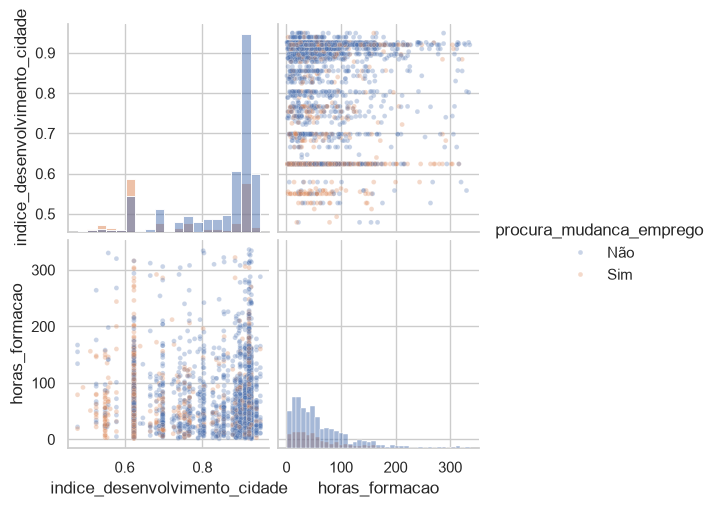

In [33]:
amostra_multivariada = df[num_cols + [target]].dropna().sample(n=min(3000, len(df[num_cols + [target]].dropna())), random_state= 42)
sns.pairplot(amostra_multivariada, vars=num_cols, hue=target, diag_kind='hist', plot_kws={'alpha': 0.3, 's': 12})
plt.show()

##### Análise e Interpretação

> *Há pares de variáveis que separam bem as classes ou relações não lineares?*

**Resposta:**

O índice de desenvolvimento diferencia mais as classes; as horas de formação acrescentam pouca separação visual. Existe ampla sobreposição, pelo que estas duas variáveis não separam perfeitamente os candidatos. O gráfico usa uma amostra aleatória para facilitar a leitura.

<hr>

**6.2 Scatter com hue**
- Scatter de duas numéricas colorido pelo target (ou por uma categórica, em clustering).

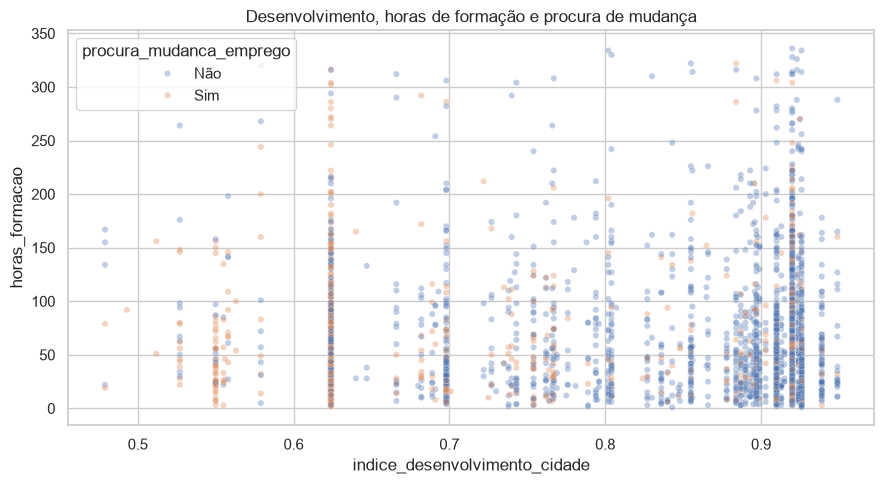

In [34]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=amostra_multivariada, x='indice_desenvolvimento_cidade', y='horas_formacao', hue=target, alpha=0.35, s=20)
plt.title('Desenvolvimento, horas de formação e procura de mudança')
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *O que se aprende ao ver três variáveis ao mesmo tempo?*

**Resposta:**

A procura de mudança concentra-se relativamente mais em índices de desenvolvimento baixos, enquanto as horas apresentam valores semelhantes nas duas classes. A sobreposição evidencia que a previsão deverá combinar outras variáveis.

<hr>

**6.3 [Classificação] Duas categóricas vs target**
- `pivot_table` com a taxa média do target cruzando duas categóricas e heatmap.

inscricao_universidade,Curso a tempo inteiro,Curso a tempo parcial,Não inscrito
experiencia_relevante,,,
Com experiência relevante,33.1,21.18,19.77
Sem experiência relevante,41.2,33.86,27.41


inscricao_universidade,Curso a tempo inteiro,Curso a tempo parcial,Não inscrito
experiencia_relevante,,,
Com experiência relevante,1444,817,11336
Sem experiência relevante,2313,381,2481


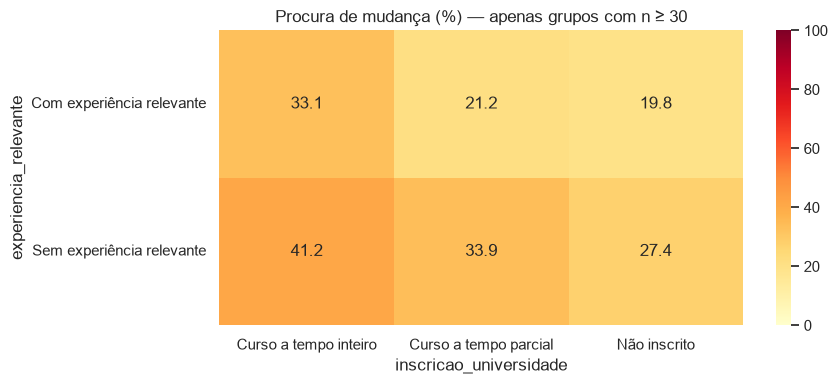

In [35]:
taxas_cruzadas = df_categorias.pivot_table(index='experiencia_relevante', columns='inscricao_universidade', values='target_binario', aggfunc='mean') * 100
contagens_cruzadas = pd.crosstab(df['experiencia_relevante'], df['inscricao_universidade'])
display(taxas_cruzadas.round(2))
display(contagens_cruzadas)
plt.figure(figsize=(9, 4))
sns.heatmap(taxas_cruzadas.where(contagens_cruzadas >= 30), annot=True, fmt='.1f', cmap='YlOrRd', vmin=0, vmax=100)
plt.title('Procura de mudança (%) — apenas grupos com n ≥ 30')
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Há combinações de categorias com comportamentos muito diferentes (interações)?*

**Resposta:**

A combinação **sem experiência relevante + curso a tempo inteiro** apresenta cerca de **41,2%** de procura de mudança; **com experiência relevante + não inscrito** apresenta **19,8%**.

<hr>

**6.4 Visão em 2D com PCA**
- Normalizar as numéricas (`StandardScaler`), projetar em 2 componentes (`PCA`) e fazer um scatter PC1 vs PC2 (colorido pelo target em classificação).

,componente,variancia_explicada_%
0,PC1,50.095986
1,PC2,49.904014


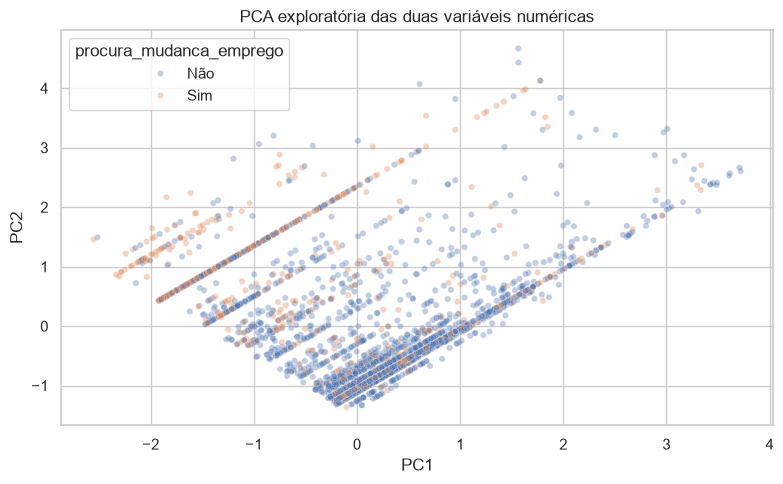

In [36]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

dados_pca = df[num_cols].dropna()
# Ajuste exclusivamente exploratório: não reutilizar na modelação.
scaler_exploratorio = StandardScaler()
pca_exploratoria = PCA(n_components=2)
componentes = pca_exploratoria.fit_transform(scaler_exploratorio.fit_transform(dados_pca))
projecao = pd.DataFrame(componentes, columns=['PC1', 'PC2'], index=dados_pca.index)
projecao[target] = df.loc[dados_pca.index, target]
display(pd.DataFrame({'componente': ['PC1', 'PC2'], 'variancia_explicada_%': pca_exploratoria.explained_variance_ratio_ * 100}))
amostra_pca = projecao.sample(n=min(3000, len(projecao)), random_state=random_state)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=amostra_pca, x='PC1', y='PC2', hue=target, alpha=0.35, s=20)
plt.title('PCA exploratória das duas variáveis numéricas')
plt.tight_layout()
plt.show()

##### Análise e Interpretação

> *Existem agrupamentos naturais? As classes parecem separáveis?*

**Resposta:**

As classes sobrepõem-se na projeção. Com apenas duas variáveis numéricas, duas componentes preservam **100%** da variância e não reduzem a dimensão; apenas transformam os eixos. Esta projeção não demonstra agrupamentos naturais nem garante separação das classes.

<hr>

### 7. Síntese da Fase de Data Understanding
<hr>

**Principais padrões identificados**
- Variáveis potencialmente mais relevantes (com evidência: gráfico, correlação, teste)
- Problemas encontrados (missing, duplicados, inconsistências, outliers, desbalanceamento, multicolinearidade)
- Hipóteses da Fase 1 confirmadas / rejeitadas
- Estrutura dos dados (linhas independentes, várias linhas por entidade, ordem temporal) e variáveis com risco de *data leakage*
- Hipóteses iniciais sobre o tipo de modelo adequado (relações lineares ou não lineares?)

#### Decisões para a fase seguinte

| Problema / observação | Evidência (secção) | Decisão para a Fase 3 |
|---|---|---|
| ex.: `Intern_ID` é identificador | 2 | remover das features |
| ex.: `Salary` assimétrica à direita | 4.1 | testar `log1p` / RobustScaler |
| ex.: classes 70/30 | 4.8 | `stratify=y`; avaliar com F1 e ROC-AUC |
| ex.: `Data_Saida` só é conhecida depois do desfecho | 2.3 | remover das features (*data leakage*) |
| | | |

***Objetivo:*** traduzir a análise exploratória em decisões para a Data Preparation.

**Resposta:**

**Principais conclusões**

- O dataset contém **19 158 candidatos**, sem duplicados de registo ou identificador. Não existe informação temporal suficiente para analisar evolução; a independência entre candidatos é uma hipótese de trabalho.
- A varíavel 'target' está desequilibrado: **75,07% Não** e **24,93% Sim**.
- O desenvolvimento da cidade apresenta a associação numérica mais relevante com o alvo (**r = −0,342**). As horas de formação têm uma associação praticamente nula, apesar da diferença de médias estatisticamente significativa.
- A experiência, a inscrição universitária e a experiência relevante diferenciam taxas de mudança. A educação também apresenta associação estatisticamente significativa.
- **H1 apoiada:** menor experiência associa-se a maior procura de mudança. **H2 apoiada:** educação e intenção de mudança estão associadas. **H3 não apoiada:** o desenvolvimento da cidade apresenta associação no sentido contrário ao previsto. São associações observacionais, não causas.
- Existem nulos em oito variáveis, sobretudo `tipo_empresa`, `dimensao_empresa`, `genero` e `area_formacao`. A exploração não permite classificar definitivamente o mecanismo de ausência.
- Há assimetria e valores extremos nas horas de formação, muitas categorias raras em cidade e sobreposição das classes nos gráficos. Não se identificou multicolinearidade entre as duas numéricas.

**Decisões para a Fase 3**

| Observação | Decisão |
|---|---|
| `id_candidato` é identificador | Excluir das variáveis explicativas. |
| Alvo binário desequilibrado | Codificar Sim/Não, dividir com estratificação e avaliar recall, precision, F1 e PR-AUC, além de ROC-AUC. |
| Valores em falta | Avaliar categoria “Desconhecido” ou imputação; ajustar a estratégia apenas no treino. |
| Experiência representada em texto | Codificar a ordem das categorias, preservando o significado de “menos de 1” e “mais de 20”, sem assumir valores exatos. |
| Cidades raras e elevada cardinalidade | Avaliar agrupamento de categorias raras com limiares definidos no treino; evitar target encoding fora de validação apropriada. |
| Horas assimétricas e valores extremos | Verificar plausibilidade; comparar transformação `log1p` ou escala robusta conforme o modelo, sem remover extremos automaticamente. |
| Possível redundância entre cidade e índice | Avaliar a utilização conjunta na modelação e validar a generalização. |
| Sobreposição de classes | Comparar uma regressão logística de referência com modelos de árvores, usando validação no treino. |
| Risco de leakage | Separar treino/teste antes de ajustar imputação, codificação, escalas, seleção de variáveis ou PCA; confirmar que todas as variáveis são conhecidas no momento da previsão. |

O scaler e a PCA desta exploração não devem ser reutilizados na modelação. O conjunto de teste deve permanecer reservado para avaliação final.

<div style="border-left:5px solid #1A59FD;background:#F3F6FF;color:#1F2A37;padding:10px 16px;margin:6px 0;border-radius:3px;font-family:Segoe UI, Arial, sans-serif;"><div style="font-weight:700;color:#1A59FD;font-size:13px;letter-spacing:0.5px;text-transform:uppercase;margin-bottom:4px;">Antes de avançar</div>Checklist de autoavaliação da fase<ul style="margin:4px 0 2px 0;"><li>Dataset descrito (origem, dimensão, dicionário de dados)</li><li>Estrutura e tipos verificados; identificadores e colunas irrelevantes assinalados</li><li>Qualidade avaliada: missing, duplicados, inconsistências</li><li>Análise univariada com interpretação (incluindo o target)</li><li>Análise bivariada e multivariada com interpretação</li><li>Gráficos adequados ao tipo de variável, com títulos e eixos legíveis</li><li>Variáveis com risco de <i>data leakage</i> e estrutura dos dados (grupos / tempo) identificadas</li><li>Síntese com decisões concretas para a Fase 3</li></ul></div>

[← Fase 1: Entendimento do Negócio](01_P_business_understanding.ipynb) &nbsp;&nbsp;|&nbsp;&nbsp; [Fase 3: Preparação dos Dados →](03_data_preparation.ipynb)

<div style="border-left:7px solid #1A59FD; background:#F3F6FF; color:#0A2540; padding:6px 14px; border-radius:4px; font-size:12px; font-family:Segoe UI, Arial, sans-serif;">Cegid Academy &nbsp;·&nbsp; AiDAPT &nbsp;·&nbsp; Template CRISP-DM v2.0 · versão formandos</div>